# 06 · Ángulo de Cobb medido en los platillos vertebrales

## Propósito

`compute-Cobb-angle.py` no mide el ángulo directamente sobre las vértebras: ajusta un plano a cada mitad de disco y busca el par con la mayor diferencia de inclinación lateral. El método de Cobb clásico, en cambio, utiliza los platillos vertebrales: el superior de la vértebra límite craneal y el inferior de la vértebra límite caudal (Cobb, 1948).

Como cada cara del disco está en contacto con un platillo, cabría esperar que sus inclinaciones fueran parecidas. Sin embargo, en el cuaderno 03 vimos que el disco 201 puede influir mucho en el resultado; en el cuaderno 05 observamos que las diferencias entre segmentadores también se concentran en el disco más caudal. Este cuaderno examina si medir directamente los platillos produce un ángulo similar al que se obtiene con las caras de los discos y dónde aparecen las diferencias.

## Qué se mide

En cada máscara manual se aísla el cuerpo de cada vértebra y se ajusta un plano a sus platillos superior e inferior, usando el mismo espacio de coordenadas que el script. A partir de esos planos se hacen dos comparaciones:

1. Se calcula la diferencia entre la inclinación de cada platillo y la de la cara del disco que está en contacto con él.
2. Se calcula un ángulo de Cobb a partir de los platillos: la mayor diferencia entre el platillo superior de una vértebra y el platillo inferior de otra situada a la misma altura o más abajo.

Después, el ángulo por platillos se compara con las dos reglas basadas en caras de disco estudiadas en el cuaderno 05. Para ello se reutilizan los planos guardados en el cuaderno 03; no es necesario volver a ejecutar el script.

La medición por platillos es una propuesta exploratoria de este proyecto. No forma parte del método publicado por van der Graaf *et al.* y todavía no se ha validado frente a mediciones realizadas por especialistas.

## Alcance

El análisis es técnico y descriptivo, y utiliza las máscaras manuales de SPIDER v4. Se incluyen 340 máscaras únicas: 107 parejas T1/T2 del mismo estudio comparten exactamente la misma máscara, por lo que no cuentan como observaciones independientes (cuaderno 02).

Las diferencias que se presentan comparan dos métodos aplicados a una misma segmentación; no permiten determinar cuál es más exacto, ya que SPIDER no incluye mediciones de Cobb realizadas por especialistas. Además, la inclinación lateral de cada platillo se estima a partir de los pocos cortes sagitales que lo atraviesan. Las caras de los discos tienen la misma limitación, analizada en el cuaderno 04 en relación con el grosor de corte. Este trabajo no constituye una validación clínica ni está destinado al diagnóstico de escoliosis.

## Fuentes

- **Dependencia:** [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`, utilizado para reorientar y remuestrear las máscaras igual que el script.
- **Planos de las caras de disco:** `planos_por_disco.csv`, generado en el cuaderno 03 con [DIAGNijmegen/cobb-angle-algorithm](https://github.com/DIAGNijmegen/cobb-angle-algorithm), commit `72c712f31e1f3069aef77b98b20af448bbc5615a`.
- **Método publicado para calcular el ángulo:** van der Graaf *et al.*, *European Radiology* (2024), [artículo completo](https://pmc.ncbi.nlm.nih.gov/articles/PMC11364572/).
- **Método de Cobb:** Cobb JR. *Outline for the study of scoliosis*. *Instructional Course Lectures* 5 (1948), 261–275.
- **Datos:** [SPIDER v4](https://doi.org/10.5281/zenodo.10159290), licencia CC BY 4.0.

## Antes de ejecutar: datos necesarios

Este cuaderno utiliza las máscaras de SPIDER v4 y los resultados generados en los cuadernos 01 y 03. Los datos no se descargan automáticamente, así que los cuatro archivos siguientes deben estar disponibles en Google Drive.

| Archivo | Ruta en Google Drive | Obligatorio |
|---|---|---|
| `masks.zip` | `MyDrive/PRL/content/datos/spider/masks/masks.zip` | Sí |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/inventario_series.csv` | Sí |
| `angulos_variantes.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/angulos_variantes.csv` | Sí |
| `planos_por_disco.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/planos_por_disco.csv` | Sí |

Los resultados de este cuaderno se guardan en:

`MyDrive/PRL/salidas/resultados_semana3/06_cobb_por_platillos/`

No se necesita GPU. Cada máscara tarda unos segundos y el procesamiento de las 340 máscaras suele tomar entre 30 y 40 minutos. Si Colab se interrumpe, se puede volver a ejecutar la configuración, la carga de máscaras, las funciones y la celda de procesamiento. El registro de series permite continuar con las que falten.

In [1]:
# 1. Dependencias: Tiger fijado al commit verificado (no a la rama, que puede moverse)
!pip -q install "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires httpx<1.0.0,>=0.28.1, but you have httpx 0.23.3 which is incompatible.
pymc 5.28.5 requires cachetools<7,>=4.2.1, but you have cachetools 7.2.6 which is incompatible.
google-adk 2.7.1 requires httpx<1,>=0.27, but you have httpx 0.23.3 which is incompatible.
gradio-client 2.7.2 requires httpx>=0.24.1, but you have httpx 0.23.3 which is incompatible.
httpcore2 2.15.1 requires h11>=0.16, but you have h11 0.14.0 which is incompatible.
langgraph-sdk 0.4.8 requires httpx>=0.25.2, but you have httpx 0.23.3 which is incompatible

In [2]:
# 2. Configuración
from pathlib import Path
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
ZIP_MASCARAS = DIR_PRL / "content" / "datos" / "spider" / "masks" / "masks.zip"
CSV_INVENTARIO = DIR_PRL / "salidas" / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
DIR_03 = DIR_PRL / "salidas" / "resultados_semana2" / "03_disco_caudal_y_variantes"     # solo lectura
CSV_VARIANTES_03 = DIR_03 / "angulos_variantes.csv"
CSV_PLANOS_03 = DIR_03 / "planos_por_disco.csv"
DIR_SALIDA = DIR_PRL / "salidas" / "resultados_semana3" / "06_cobb_por_platillos"
DIR_LOCAL = Path("/content/mascaras_unicas")       # copia local: leer de Drive en cada serie es lento

COMMIT_TIGER = "4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
COMMIT_SCRIPT = "72c712f31e1f3069aef77b98b20af448bbc5615a"   # el que produjo los planos del cuaderno 03
MD5_MASKS_ZIP = "49861ff25a0108b3b69d0ce808ae51dc"   # descarga verificada contra Zenodo el 2-oct-2026
N_ESPERADO = 447                                      # series de SPIDER según el cuaderno 01
N_UNICAS = 340                                        # máscaras distintas según el cuaderno 03
B_BOOTSTRAP, SEMILLA = 2000, 2026                     # igual que en el cuaderno 05

for archivo in (ZIP_MASCARAS, CSV_INVENTARIO, CSV_VARIANTES_03, CSV_PLANOS_03):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

inventario = pd.read_csv(CSV_INVENTARIO, dtype={"serie": str}).set_index("serie")
variantes = pd.read_csv(CSV_VARIANTES_03, dtype={"serie": str})
planos_disco = (pd.read_csv(CSV_PLANOS_03, dtype={"serie": str})
                  .drop_duplicates(["serie", "disco", "cara"], keep="last"))
unicas = sorted(variantes.loc[variantes["mascara_unica"], "serie"])
assert len(variantes) == N_ESPERADO, f"angulos_variantes.csv debería tener {N_ESPERADO} series"
assert len(unicas) == N_UNICAS, f"Se esperaban {N_UNICAS} máscaras únicas y hay {len(unicas)}"
print(f"Máscaras únicas: {len(unicas)} | caras de disco del cuaderno 03: {len(planos_disco)}")
print("Salida:", DIR_SALIDA)

Mounted at /content/drive
Máscaras únicas: 340 | caras de disco del cuaderno 03: 6294
Salida: /content/drive/MyDrive/PRL/salidas/resultados_semana3/06_cobb_por_platillos


## Verificación de las máscaras y copia local

Antes de trabajar con las máscaras, se comprueba que el archivo `masks.zip` tenga la misma huella MD5 que se verificó con Zenodo. Después, se verifica que cada máscara extraída coincida con la huella registrada en `angulos_variantes.csv` durante el cuaderno 03.

In [3]:
# 3. Verificar masks.zip y extraer las máscaras únicas a disco local
import hashlib, zipfile

def md5_archivo(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

assert md5_archivo(ZIP_MASCARAS) == MD5_MASKS_ZIP, "masks.zip no coincide con la huella verificada contra Zenodo"
huellas = variantes.set_index("serie")["mascara_md5"]
DIR_LOCAL.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_MASCARAS) as z:
    miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
    assert len(miembros) == N_ESPERADO, f"Se esperaban {N_ESPERADO} máscaras en el zip y hay {len(miembros)}"
    for s in unicas:
        datos = z.read(miembros[f"{s}.mha"])
        assert hashlib.md5(datos).hexdigest() == huellas[s], f"{s}: la máscara no coincide con la del cuaderno 03"
        (DIR_LOCAL / f"{s}.mha").write_bytes(datos)
print(f"{len(unicas)} máscaras únicas en {DIR_LOCAL}, idénticas a las que usó el cuaderno 03")

340 máscaras únicas en /content/mascaras_unicas, idénticas a las que usó el cuaderno 03


## Cómo se mide cada platillo

Todas las mediciones se realizan en el mismo espacio de coordenadas que utiliza el script. Para ello, la máscara se reorienta y se remuestrea a vóxeles de 0,5 mm con las funciones de Tiger. Así, $x$ representa el eje lateral, $y$ el anteroposterior y $z$ el craneocaudal, y los planos de los platillos quedan en el mismo sistema que los planos de las caras de disco del cuaderno 03.

**Aislamiento del cuerpo vertebral.** Las máscaras de SPIDER incluyen la vértebra completa, también el arco posterior. Si se usara toda la superficie, algunas zonas horizontales del arco podrían confundirse con los platillos. Para evitarlo, en cada corte axial se identifica el borde del canal (etiqueta 100) orientado hacia los cuerpos vertebrales y se conservan los vóxeles que quedan por delante de ese borde. De esa región se selecciona el mayor componente conexo. La posición anterior se determina con los discos, que están delante del canal, en lugar de asumir de antemano la orientación del eje $y$.

**Identificación de los platillos.** La superficie del cuerpo vertebral se reconstruye mediante *marching cubes*, igual que en el script para los discos. Se seleccionan los puntos cuya normal forma menos de 45° con el eje de la vértebra. Los que quedan por encima del centroide se asignan al platillo superior; los que quedan por debajo, al inferior. A cada grupo se le ajusta un plano mediante PCA. La normal se orienta hacia arriba ($n_z \geq 0$), y la inclinación se calcula con la misma fórmula del script, $\theta = \arctan(n_x/n_z)$, para que ambas mediciones puedan compararse.

**Contacto con el disco.** Para formar parte del platillo, cada punto debe encontrarse a menos de 3 mm del disco en contacto con esa superficie. Esta condición se añadió después de una primera ejecución que falló en `53_t1`: allí, la etiqueta de la vértebra 1 rodea al disco 201 y, sin el filtro, el plano mezclaba la superficie junto al disco con el borde inferior del tejido que queda debajo (celda 10b). Por definición, el platillo es la superficie vertebral que contacta con el disco; exigir ese contacto no se diseñó solo para resolver ese caso. El umbral concreto de 3 mm sí es una decisión metodológica de este cuaderno.

**Estimación del eje vertebral.** El eje se estima en dos pasos. Primero se calcula la dirección entre los centroides de los discos inferior y superior, eliminando la componente lateral; esto permite tener en cuenta la lordosis. Después se usa la normal media de los dos platillos identificados en el primer paso, incorporando también la inclinación lateral de la vértebra. Esta estrategia se eligió tras una prueba previa con tres máscaras: el eje calculado a partir de la forma del cuerpo (dirección de menor varianza) se desviaba hasta unos 40° en vértebras muy inclinadas. La razón es que un cuerpo lumbar no es mucho más bajo que profundo, mientras que los centroides de los discos pueden presentar varios grados de variación lateral por el grosor de corte.

**Disco vecino y exclusiones.** El disco que contacta con cada platillo se identifica según la posición vertical de los cuerpos y los discos, no por el número de etiqueta. Si un platillo no tiene un disco vecino, se excluye del análisis. Esto ocurre normalmente con el platillo superior de la vértebra más craneal, que suele quedar cortada por el campo de visión.

**Cálculo del ángulo de Cobb por platillos.** Con las vértebras numeradas de caudal a craneal, como en SPIDER, el ángulo se define como:

$$
C_{\mathrm{plat}} = \max_{L \leq U} \left| \theta_{\mathrm{sup},U} - \theta_{\mathrm{inf},L} \right|
$$

El platillo inferior de la vértebra $L$ contacta con la cara superior del disco situado debajo; el platillo superior de la vértebra $U$ contacta con la cara inferior del disco situado encima. Por eso, cada par $(L,U)$ se puede relacionar con un par de discos de la regla del artículo. Cuando $L=U$, se comparan dos discos consecutivos, una posibilidad que la regla del artículo también admite.

La regla del script utiliza las caras opuestas de cada disco. Por esta razón, la cara inferior del disco 201, la que contacta con el sacro, no tiene un platillo vertebral equivalente en estas máscaras, ya que SPIDER no segmenta el sacro.

In [4]:
# 4. Funciones: cuerpo vertebral, platillos y ángulo de Cobb por platillos
import numpy as np
from scipy import ndimage
from skimage import measure
from tiger.io import read_image
from tiger.resampling import reorient_image, resample_mask

CANAL = 100
ANGULO_MAX_PLATILLO = 45.0     # grados entre la normal de la superficie y el eje de la vértebra para contar como platillo
MIN_VERTICES = 50              # con menos puntos no se ajusta el plano
DIST_MAX_DISCO_MM = 3.0        # un punto del platillo debe estar a menos de esto de su disco vecino
MM_POR_VOXEL = 0.5             # el espacio del script tiene vóxeles de 0,5 mm

def en_espacio_del_script(ruta):
    "Máscara reorientada y remuestreada a 0,5 mm, igual que en compute-Cobb-angle.py (ejes del arreglo: x lateral, y anteroposterior, z craneocaudal)."
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    return resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))

def signo_anterior(mascara):
    "+1 o -1: hacia dónde crece el eje y desde el canal hacia los cuerpos. Se decide con los discos, que están delante del canal."
    return 1 if np.nonzero(mascara > 200)[1].mean() > np.nonzero(mascara == CANAL)[1].mean() else -1

def borde_del_canal(mascara, signo):
    "Para cada corte axial (z), la coordenada y del borde del canal que mira hacia los cuerpos; se interpola donde no hay canal."
    canal = mascara == CANAL
    z_con = np.nonzero(canal.any(axis=(0, 1)))[0]
    bordes = []
    for z in z_con:
        ys = np.nonzero(canal[:, :, z].any(axis=0))[0]
        bordes.append(ys.max() if signo > 0 else ys.min())
    return np.interp(np.arange(mascara.shape[2]), z_con, bordes)

def cuerpo_vertebral(mascara, k, caja, borde, signo):
    """Vóxeles de la vértebra k que quedan delante del canal, dentro de la caja de la vértebra; se conserva el mayor
    componente conexo. Devuelve el cuerpo recortado y el desplazamiento de la caja."""
    y = np.arange(caja[1].start, caja[1].stop)[None, :, None]
    b = borde[caja[2]][None, None, :]
    cuerpo = (mascara[caja] == k) & ((y > b) if signo > 0 else (y < b))
    etiquetas, n = ndimage.label(cuerpo)
    if n > 1:
        cuerpo = etiquetas == (int(np.argmax(np.bincount(etiquetas.ravel())[1:])) + 1)
    return cuerpo, np.array([sl.start for sl in caja])

def ajustar_plano(puntos):
    "Plano por PCA: normal = dirección de menor varianza, orientada con nz >= 0; punto = centroide."
    c = puntos.mean(axis=0)
    _, vecs = np.linalg.eigh(np.cov((puntos - c).T))
    n = vecs[:, 0]
    return (n if n[2] >= 0 else -n), c

def eje_sagital(centro, c_abajo, c_arriba):
    """Primera estimación del eje de la vértebra: del disco de abajo al de arriba (o del cuerpo al único disco vecino),
    sin su componente lateral. Recoge la lordosis sin que el ruido lateral de los centroides lo incline."""
    if c_abajo is not None and c_arriba is not None:
        v = c_arriba - c_abajo
    elif c_arriba is not None:
        v = c_arriba - centro
    elif c_abajo is not None:
        v = centro - c_abajo
    else:
        v = np.array([0.0, 0.0, 1.0])
    v = np.array([0.0, v[1], v[2]])
    v /= np.linalg.norm(v)
    return v if v[2] >= 0 else -v

def distancia_a_disco(mascara, disco, cache):
    """Distancia (en vóxeles) al disco, calculada una sola vez por disco y solo en una caja alrededor de él.
    Devuelve el campo de distancias y la esquina de la caja; fuera de la caja, el punto está demasiado lejos."""
    if disco not in cache:
        margen = int(np.ceil(DIST_MAX_DISCO_MM / MM_POR_VOXEL)) + 2
        caja = ndimage.find_objects((mascara == disco).astype(np.uint8))[0]
        ini = np.array([max(sl.start - margen, 0) for sl in caja])
        fin = np.array([min(sl.stop + margen, n) for sl, n in zip(caja, mascara.shape)])
        sub = mascara[tuple(slice(i, f) for i, f in zip(ini, fin))]
        cache[disco] = (ndimage.distance_transform_edt(sub != disco), ini)
    return cache[disco]

def platillos_de(cuerpo, desp, eje, mascara, discos, cache, devolver_puntos=False, dist_max=DIST_MAX_DISCO_MM):
    """Un plano para el platillo superior y otro para el inferior. Un punto de la superficie del cuerpo (marching cubes)
    cuenta como platillo si su normal forma menos de ANGULO_MAX_PLATILLO con el eje, está del lado correspondiente del
    centroide y queda a menos de dist_max (mm) del disco que toca ese platillo; con dist_max=None no se aplica esta
    condición (así funcionaba la primera versión). discos = {"superior": etiqueta o None, "inferior": etiqueta o None};
    sin disco vecino no hay platillo."""
    centro = np.argwhere(cuerpo).mean(axis=0) + desp
    verts, _, normales, _ = measure.marching_cubes(np.pad(cuerpo, 1).astype(np.uint8), 0.5)
    verts += desp - 1                                      # deshace el relleno y vuelve a coordenadas de la máscara completa
    largo = np.linalg.norm(normales, axis=1, keepdims=True)
    normales = np.divide(normales, largo, out=np.zeros_like(normales), where=largo > 0)
    alineados = np.abs(normales @ eje) >= np.cos(np.radians(ANGULO_MAX_PLATILLO))
    lado = (verts - centro) @ eje
    salida, puntos = {}, {}
    for nombre, sel in (("superior", alineados & (lado > 0)), ("inferior", alineados & (lado < 0))):
        disco = discos.get(nombre)
        if disco is None:
            salida[nombre] = None
            continue
        if dist_max is not None:
            dist, ini = distancia_a_disco(mascara, disco, cache)
            idx = np.round(verts - ini).astype(int)
            dentro = np.all((idx >= 0) & (idx < np.array(dist.shape)), axis=1)
            cerca = np.zeros(len(verts), bool)
            cerca[dentro] = dist[tuple(idx[dentro].T)] * MM_POR_VOXEL <= dist_max
            sel = sel & cerca
        puntos[nombre] = verts[sel]
        if sel.sum() < MIN_VERTICES:
            salida[nombre] = None
            continue
        n, p = ajustar_plano(verts[sel])
        salida[nombre] = {"nx": n[0], "ny": n[1], "nz": n[2], "px": p[0], "py": p[1], "pz": p[2],
                          "n_vertices": int(sel.sum()),
                          "angulo_coronal": float(np.degrees(np.arctan(n[0] / n[2]))),
                          "inclinacion_sagital": float(np.degrees(np.arctan(n[1] / n[2])))}
    return (salida, puntos) if devolver_puntos else salida

def ajuste_de_vertebra(mascara, cuerpo, desp, centro, c_abajo, c_arriba, discos, cache=None, devolver_puntos=False,
                       dist_max=DIST_MAX_DISCO_MM):
    "Las dos pasadas del ajuste: eje sagital entre discos y, después, eje = normal media de los platillos encontrados."
    cache = {} if cache is None else cache
    eje = eje_sagital(centro, c_abajo, c_arriba)
    res = platillos_de(cuerpo, desp, eje, mascara, discos, cache, dist_max=dist_max)
    normales = [np.array([res[c][q] for q in ("nx", "ny", "nz")]) for c in ("superior", "inferior") if res[c] is not None]
    if normales:
        eje = np.mean(normales, axis=0)
        eje /= np.linalg.norm(eje)
    return platillos_de(cuerpo, desp, eje, mascara, discos, cache, devolver_puntos, dist_max)

def filas_platillos(mascara, **ident):
    """Una fila por platillo de cada vértebra, con el disco vecino de ese lado. Los vecinos salen del orden por altura
    de los cuerpos y los discos, no del número de etiqueta. Un platillo sin disco al lado (por ejemplo, el superior de la
    vértebra más craneal, cortada por el campo de visión) queda excluido, y uno con disco pero con menos de MIN_VERTICES
    puntos cerca de él queda sin plano."""
    signo = signo_anterior(mascara)
    borde = borde_del_canal(mascara, signo)
    cajas = ndimage.find_objects(mascara.astype(np.int32))
    presentes = [l + 1 for l, c in enumerate(cajas) if c is not None and l + 1 != CANAL]
    cuerpos, centros = {}, {}
    for l in presentes:
        caja = cajas[l - 1]
        if l < CANAL:
            cuerpo, desp = cuerpo_vertebral(mascara, l, caja, borde, signo)
            if cuerpo.sum() == 0:
                continue
            cuerpos[l] = (cuerpo, desp)
            centros[l] = np.argwhere(cuerpo).mean(axis=0) + desp
        else:
            centros[l] = np.argwhere(mascara[caja] == l).mean(axis=0) + np.array([sl.start for sl in caja])
    orden = sorted(centros, key=lambda l: centros[l][2])
    filas, cache = [], {}
    for i, k in enumerate(orden):
        if k > CANAL:
            continue
        abajo = orden[i - 1] if i > 0 and orden[i - 1] > 200 else None
        arriba = orden[i + 1] if i + 1 < len(orden) and orden[i + 1] > 200 else None
        cuerpo, desp = cuerpos[k]
        res = ajuste_de_vertebra(mascara, cuerpo, desp, centros[k], centros.get(abajo), centros.get(arriba),
                                 {"superior": arriba, "inferior": abajo}, cache)
        for cara, disco in (("superior", arriba), ("inferior", abajo)):
            fila = {**ident, "vertebra": k, "platillo": cara, "disco_vecino": disco, "voxeles_cuerpo": int(cuerpo.sum()),
                    "excluido_sin_disco": disco is None}
            if res[cara] is not None and disco is not None:
                fila.update(res[cara])
            filas.append(fila)
    return filas

def cobb_por_platillos(platillos):
    """Máximo, entre vértebras L <= U (numeración de SPIDER, de caudal a craneal), de |platillo superior de U − platillo
    inferior de L|. Con L = U es la cuña de una sola vértebra. Devuelve (ángulo, L, U)."""
    p = platillos.dropna(subset=["angulo_coronal"])
    sup = p[p["platillo"] == "superior"].set_index("vertebra")["angulo_coronal"]
    inf = p[p["platillo"] == "inferior"].set_index("vertebra")["angulo_coronal"]
    mejor = (np.nan, np.nan, np.nan)
    for L in sorted(inf.index):
        for U in sorted(sup.index):
            if L <= U:
                v = abs(sup[U] - inf[L])
                if np.isnan(mejor[0]) or v > mejor[0]:
                    mejor = (float(v), int(L), int(U))
    return mejor

## Prueba con una serie y panel de control

Antes de procesar las 340 máscaras, la celda 5 mide los platillos de `162_t1`. Se eligió esta serie porque en el cuaderno 03 el disco 201 tuvo una influencia especialmente grande en el ángulo calculado. El panel permite revisar visualmente si el cuerpo vertebral quedó bien aislado y si los planos ajustados siguen la superficie de los platillos.

162_t1: 11.9 s


,vertebra,platillo,disco_vecino,excluido_sin_disco,n_vertices,angulo_coronal,inclinacion_sagital
0,1,superior,202,False,8291,5.43,-22.77
1,1,inferior,201,False,5403,19.65,-42.26
2,2,superior,203,False,6663,-1.08,-9.97
3,2,inferior,202,False,6609,2.86,-11.29
4,3,superior,204,False,6345,-4.06,-0.01
5,3,inferior,203,False,6213,-3.65,-2.92
6,4,superior,205,False,7410,-3.53,4.43
7,4,inferior,204,False,6556,-4.47,7.03
8,5,superior,206,False,6483,2.96,0.77
9,5,inferior,205,False,7319,-0.33,8.24


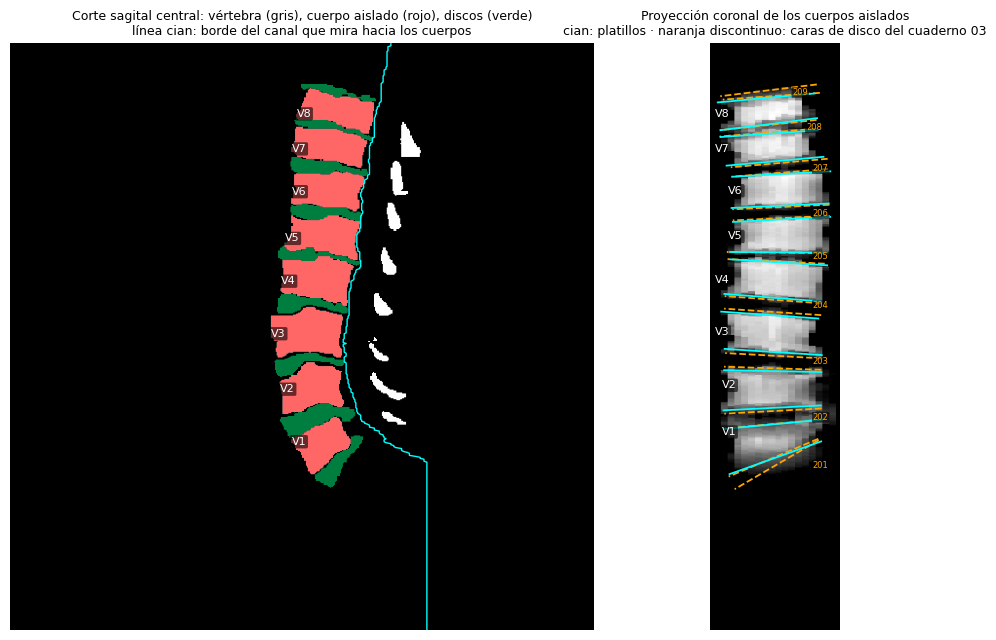

In [5]:
# 5. Prueba en 162_t1 y panel de control del cuerpo aislado y de los platillos
import time
import matplotlib.pyplot as plt
SERIE_CONTROL = "162_t1"

def cuerpos_de(mascara):
    "Máscara booleana con los cuerpos de todas las vértebras, y el borde del canal, para dibujar."
    signo = signo_anterior(mascara)
    borde = borde_del_canal(mascara, signo)
    cajas = ndimage.find_objects(mascara.astype(np.int32))
    cuerpos = np.zeros(mascara.shape, bool)
    for l in range(1, min(CANAL, len(cajas) + 1)):
        if cajas[l - 1] is not None:
            c, d = cuerpo_vertebral(mascara, l, cajas[l - 1], borde, signo)
            cuerpos[tuple(slice(o, o + n) for o, n in zip(d, c.shape))] |= c
    return cuerpos, borde

def dibujar_plano(ax, fila, color, largo=50, **kw):
    "Traza en la proyección coronal la línea de un plano (normal nx, nz; punto px, pz), en vóxeles de 0,5 mm."
    d = np.array([fila["nz"], -fila["nx"]]) / np.hypot(fila["nx"], fila["nz"])
    ax.plot([fila["px"] - largo * d[0], fila["px"] + largo * d[0]],
            [fila["pz"] - largo * d[1], fila["pz"] + largo * d[1]], color=color, lw=1.3, **kw)

def rotular_vertebras(ax, mascara, vista, x_corte=None, discos=False):
    '''Escribe la etiqueta de SPIDER sobre cada vértebra (V1 = la más caudal; no es un nivel anatómico) y, si
    discos=True, el número de cada disco. vista: "coronal" (proyección) o "sagital" (corte en x_corte).
    Se llama después de invertir el eje, si se invierte: las vértebras van al borde izquierdo y los discos al derecho.'''
    datos = mascara[x_corte] if vista == "sagital" else mascara
    invertido = ax.xaxis_inverted()
    for l in (int(v) for v in np.unique(datos)):
        es_disco = l > 200
        if l == 0 or l == CANAL or (es_disco and not discos):
            continue
        idx = np.argwhere(datos == l)
        h, z = (idx[:, 0], idx[:, 1]) if vista == "sagital" else (idx[:, 0], idx[:, 2])
        izquierda, derecha = (h.max(), h.min()) if invertido else (h.min(), h.max())
        if es_disco:
            ax.text(derecha, np.median(z), str(l), fontsize=6, color="orange", ha="right", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.1", "fc": "black", "ec": "none", "alpha": 0.6})
        else:
            ax.text(izquierda, np.median(z), f"V{l}", fontsize=8, color="white", ha="left", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})

t0 = time.time()
mascara = en_espacio_del_script(DIR_LOCAL / f"{SERIE_CONTROL}.mha")
plat_control = pd.DataFrame(filas_platillos(mascara, serie=SERIE_CONTROL))
print(f"{SERIE_CONTROL}: {time.time() - t0:.1f} s")
display(plat_control[["vertebra", "platillo", "disco_vecino", "excluido_sin_disco", "n_vertices",
                      "angulo_coronal", "inclinacion_sagital"]].round(2))

cuerpos, borde = cuerpos_de(mascara)
caras = planos_disco[planos_disco["serie"] == SERIE_CONTROL]
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
xc = int(round(np.argwhere(cuerpos)[:, 0].mean()))
ax = axes[0]
ax.imshow(((mascara[xc] > 0) & (mascara[xc] < CANAL)).T, cmap="gray", origin="lower")
ax.imshow(np.ma.masked_equal(cuerpos[xc].T, 0), cmap="autumn", alpha=0.6, origin="lower")
ax.imshow(np.ma.masked_equal((mascara[xc] > 200).T, 0), cmap="winter", vmin=0, vmax=1, alpha=0.5, origin="lower")
ax.plot(borde, np.arange(mascara.shape[2]), color="cyan", lw=1)
rotular_vertebras(ax, mascara, "sagital", x_corte=xc)
ax.set_title("Corte sagital central: vértebra (gris), cuerpo aislado (rojo), discos (verde)\n"
             "línea cian: borde del canal que mira hacia los cuerpos", fontsize=9)
ax.axis("off")
ax = axes[1]
ax.imshow(cuerpos.sum(1).T, cmap="gray", origin="lower")
for _, f in caras.iterrows():
    dibujar_plano(ax, f, "orange", ls="--")
for _, f in plat_control.dropna(subset=["angulo_coronal"]).iterrows():
    dibujar_plano(ax, f, "cyan")
ax.invert_xaxis()
rotular_vertebras(ax, mascara, "coronal", discos=True)
ax.set_title("Proyección coronal de los cuerpos aislados\ncian: platillos · naranja discontinuo: caras de disco del cuaderno 03", fontsize=9)
ax.axis("off")
plt.tight_layout()
fig.savefig(DIR_SALIDA / f"panel_control_{SERIE_CONTROL}.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer la tabla y el panel.** Cada fila de la tabla corresponde a un platillo de `162_t1` e indica el disco con el que contacta, el número de puntos utilizados para ajustar el plano y sus inclinaciones lateral y sagital. A la izquierda se muestra el corte sagital central, que permite ver qué parte de cada vértebra se conservó como cuerpo. A la derecha aparece la proyección coronal de esos cuerpos, con los planos de los platillos y los planos de las caras de disco del cuaderno 03 superpuestos. La cabeza queda orientada hacia arriba, igual que en el panel del cuaderno 05.

**Resultados.** En el corte sagital, el límite del canal excluye el arco posterior y conserva el cuerpo completo de las ocho vértebras de `162_t1`. En la proyección coronal, las inclinaciones de los platillos son muy parecidas a las de las caras de disco con las que contactan: en la zona lumbar media, la diferencia no supera 1,5°.

La diferencia mayor aparece en el extremo caudal. El platillo inferior de V1 se inclina 19,7°; la cara superior del disco 201, 22,8°; y la cara inferior de ese mismo disco, 30,3°. Esta última es la superficie que contacta con el sacro y la que utiliza la regla del script, pero no tiene un platillo vertebral correspondiente para compararla.

Las etiquetas V1, V2… siguen la numeración de SPIDER desde la vértebra más caudal; no representan niveles anatómicos y V1 no equivale necesariamente a L5. Los números naranjas identifican los discos.

## Platillos de las 340 máscaras únicas

La celda 6 procesa las máscaras una por una. Para cada serie, primero añade los platillos calculados a `platillos_por_vertebra.csv` y después registra la serie en `registro_platillos.csv`. Si Colab se interrumpe entre ambas escrituras, la serie puede volver a procesarse; la celda 7 elimina las filas duplicadas antes de continuar.

In [6]:
# 6. Platillos de las 340 máscaras únicas (retoma donde iba si se interrumpe)
import datetime
CSV_PLATILLOS = DIR_SALIDA / "platillos_por_vertebra.csv"
CSV_REGISTRO = DIR_SALIDA / "registro_platillos.csv"

def anotar(csv, filas):
    if filas:
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)

hechas = (set(pd.read_csv(CSV_REGISTRO, dtype={"serie": str}).query("estado == 'ok'")["serie"])
          if CSV_REGISTRO.exists() else set())
pendientes = [s for s in unicas if s not in hechas]
print(f"Hechas: {len(hechas)} | pendientes: {len(pendientes)}")

inicio = time.time()
for k, s in enumerate(pendientes, 1):
    t0, filas, error = time.time(), [], ""
    try:
        filas = filas_platillos(en_espacio_del_script(DIR_LOCAL / f"{s}.mha"), serie=s)
        estado = "ok"
    except Exception as e:
        estado, error = "error", f"{type(e).__name__}: {e}"[:300]
    anotar(CSV_PLATILLOS, filas)
    anotar(CSV_REGISTRO, [{"serie": s, "estado": estado, "n_vertebras": len({f["vertebra"] for f in filas}),
                           "segundos": round(time.time() - t0, 1),
                           "fecha": datetime.datetime.now().isoformat(timespec="seconds"), "error": error}])
    if k % 25 == 0 or estado != "ok":
        print(f"[{k}/{len(pendientes)}] {s}: {estado} {error} | {(time.time() - inicio) / 60:.0f} min")
print("Listo.")

Hechas: 340 | pendientes: 0
Listo.


## Resultados por serie y controles de calidad

Antes de interpretar los resultados, la celda 7 realiza cuatro comprobaciones:

1. **Integridad del cálculo:** las 340 máscaras únicas están procesadas, todas las normales cumplen $n_z > 0$ y el valor de $\arctan(n_x/n_z)$ coincide con el ángulo guardado.
2. **Correspondencia del disco vecino:** se cuenta cuántos platillos tienen como vecino un disco distinto del que corresponde a la numeración de SPIDER. Para la vértebra $k$, se espera el disco $200+k$ debajo y el $201+k$ encima. Una discrepancia no detiene la ejecución, pero requiere revisar la máscara afectada.
3. **Disponibilidad del plano de disco:** cada platillo con un disco vecino tiene registrada en `planos_por_disco.csv` la cara de disco correspondiente.
4. **Reproducción del resultado original:** al recalcular la regla del script con los planos del cuaderno 03, se obtiene el ángulo registrado en `angulos_variantes.csv`.

El archivo `cobb_por_serie.csv` contiene una fila por máscara única, con el ángulo por platillos, el par de vértebras que lo define, el par de discos equivalente y los ángulos y pares de las dos reglas basadas en caras de disco. El archivo `platillo_vs_cara_de_disco.csv` contiene una fila por platillo e identifica la cara de disco con la que se compara.

In [7]:
# 7. Tabla por serie y controles
def angulo_por_regla(caras, regla):
    '''Máximo ángulo entre pares de discos a < b, con el mismo desempate que el script (cuaderno 05).
    regla 'script':   cara inferior del disco caudal (a) contra cara superior del craneal (b).
    regla 'articulo': cara superior del disco caudal (a) contra cara inferior del craneal (b).'''
    inf = caras[caras["cara"] == "inferior"].set_index("disco")["angulo_coronal_script"]
    sup = caras[caras["cara"] == "superior"].set_index("disco")["angulo_coronal_script"]
    labels = sorted(int(l) for l in inf.index)
    mejor = (np.nan, np.nan, np.nan)
    for i, a in enumerate(labels):
        for b in labels[i + 1:]:
            v = abs(sup[b] - inf[a]) if regla == "script" else abs(sup[a] - inf[b])
            if np.isnan(mejor[0]) or v > mejor[0]:
                mejor = (float(v), a, b)
    return mejor

plat = (pd.read_csv(CSV_PLATILLOS, dtype={"serie": str})
          .drop_duplicates(["serie", "vertebra", "platillo"], keep="last"))
registro = pd.read_csv(CSV_REGISTRO, dtype={"serie": str}).drop_duplicates("serie", keep="last")
print("Series por estado:\n" + registro["estado"].value_counts().to_string())
assert set(registro.loc[registro["estado"] == "ok", "serie"]) == set(unicas), "Faltan series: vuelve a correr la celda 6"

# Control 1: normales hacia arriba y ángulo reproducible desde ellas
validos = plat.dropna(subset=["angulo_coronal"]).copy()
assert (validos["nz"] > 0).all(), "Hay normales con nz <= 0"
dif_formula = (np.degrees(np.arctan(validos["nx"] / validos["nz"])) - validos["angulo_coronal"]).abs().max()
print(f"\nControl 1 · |atan(nx/nz) − ángulo guardado|, máximo en {len(validos)} platillos: {dif_formula:.2e}°")
assert dif_formula < 1e-9

# Control 2: el disco vecino encontrado por altura frente al que indica la numeración de SPIDER
esperado = np.where(plat["platillo"] == "inferior", 200 + plat["vertebra"], 201 + plat["vertebra"])
distintos = plat[plat["disco_vecino"].notna() & (plat["disco_vecino"] != esperado)]
print(f"Control 2 · platillos cuyo disco vecino no es el que indica la numeración: {len(distintos)}"
      + (f" (series: {sorted(distintos['serie'].unique())})" if len(distintos) else ""))

# Control 3: cada platillo con disco vecino tiene su cara de disco en el cuaderno 03
caras_idx = planos_disco.set_index(["serie", "disco", "cara"])
validos["cara_disco"] = np.where(validos["platillo"] == "superior", "inferior", "superior")
claves = list(zip(validos["serie"], validos["disco_vecino"].astype(int), validos["cara_disco"]))
faltan = [c for c in claves if c not in caras_idx.index]
assert not faltan, f"Platillos sin su cara de disco en el cuaderno 03: {faltan[:5]}"
print(f"Control 3 · los {len(claves)} platillos con disco vecino tienen su cara de disco en el cuaderno 03")
validos["angulo_cara_disco"] = caras_idx.loc[claves, "angulo_coronal_script"].to_numpy()
validos["sagital_cara_disco"] = caras_idx.loc[claves, "inclinacion_sagital"].to_numpy()
validos["dif_platillo_menos_disco"] = validos["angulo_coronal"] - validos["angulo_cara_disco"]
validos = validos.join(inventario[["estudio", "secuencia", "subset"]], on="serie")

excluidos = plat[plat["excluido_sin_disco"]]
sin_plano = plat[~plat["excluido_sin_disco"] & plat["angulo_coronal"].isna()]
print(f"\nPlatillos excluidos por no tener disco al lado: {len(excluidos)} "
      f"({(excluidos['platillo'] == 'superior').sum()} superiores, {(excluidos['platillo'] == 'inferior').sum()} inferiores)")
print(f"Platillos con disco al lado pero con menos de {MIN_VERTICES} puntos: {len(sin_plano)}")

# Tabla por serie
filas = []
for s, g in validos.groupby("serie"):
    c_plat, L, U = cobb_por_platillos(g)
    vecino = g.set_index(["vertebra", "platillo"])["disco_vecino"]
    caras = planos_disco[planos_disco["serie"] == s]
    c_art, a1, a2 = angulo_por_regla(caras, "articulo")
    c_scr, s1, s2 = angulo_por_regla(caras, "script")
    filas.append({"serie": s, "n_vertebras": g["vertebra"].nunique(),
                  "cobb_platillos": c_plat, "vertebra_inf": L, "vertebra_sup": U,
                  "disco_inf_equivalente": vecino.get((L, "inferior"), np.nan) if not np.isnan(c_plat) else np.nan,
                  "disco_sup_equivalente": vecino.get((U, "superior"), np.nan) if not np.isnan(c_plat) else np.nan,
                  "cobb_articulo": c_art, "disco_inf_articulo": a1, "disco_sup_articulo": a2,
                  "cobb_script": c_scr, "disco_inf_script": s1, "disco_sup_script": s2})
por_serie = pd.DataFrame(filas).join(inventario[["estudio", "secuencia", "subset"]], on="serie")
por_serie["una_sola_vertebra"] = por_serie["vertebra_inf"] == por_serie["vertebra_sup"]
por_serie["mismo_par_articulo"] = ((por_serie["disco_inf_equivalente"] == por_serie["disco_inf_articulo"])
                                   & (por_serie["disco_sup_equivalente"] == por_serie["disco_sup_articulo"]))
por_serie["dif_vs_articulo"] = por_serie["cobb_platillos"] - por_serie["cobb_articulo"]
por_serie["dif_vs_script"] = por_serie["cobb_platillos"] - por_serie["cobb_script"]

# Control 4: la regla del script reproduce el ángulo original del cuaderno 03
original = variantes.set_index("serie").loc[por_serie["serie"], "angulo_original"].to_numpy()
dif_03 = np.nanmax(np.abs(por_serie["cobb_script"].to_numpy() - original))
print(f"Control 4 · |regla del script − ángulo original del cuaderno 03|, máximo en {len(por_serie)} series: {dif_03:.2e}°")
assert dif_03 < 1e-9

por_serie.to_csv(DIR_SALIDA / "cobb_por_serie.csv", index=False)
validos.to_csv(DIR_SALIDA / "platillo_vs_cara_de_disco.csv", index=False)
print(f"\nSeries con ángulo por platillos: {por_serie['cobb_platillos'].notna().sum()} de {len(por_serie)}")

Series por estado:
estado
ok    340

Control 1 · |atan(nx/nz) − ángulo guardado|, máximo en 4469 platillos: 1.07e-14°
Control 2 · platillos cuyo disco vecino no es el que indica la numeración: 0
Control 3 · los 4469 platillos con disco vecino tienen su cara de disco en el cuaderno 03

Platillos excluidos por no tener disco al lado: 317 (317 superiores, 0 inferiores)
Platillos con disco al lado pero con menos de 50 puntos: 0
Control 4 · |regla del script − ángulo original del cuaderno 03|, máximo en 340 series: 3.55e-15°

Series con ángulo por platillos: 340 de 340


**Cómo leer la salida.** Los controles aparecen en orden. Si falla el control 1, 3 o 4, la celda se detiene. Después se informa cuántos platillos se excluyeron: los que no tienen un disco vecino y los que, aun teniéndolo, no disponen de suficientes puntos para ajustar el plano.

**Resultados.** Las 340 máscaras únicas se procesaron sin errores y los cuatro controles se superaron. En ningún caso el disco vecino identificado por su posición difiere del que corresponde a la numeración de SPIDER.

Se excluyeron 317 platillos, todos superiores. En 317 de las 340 máscaras, se trata del platillo superior de la vértebra más craneal, que no tiene un disco por encima. En las 23 máscaras restantes sí aparece un disco por encima de esa vértebra. La condición de contacto permitió ajustar un plano en todos los demás platillos; por tanto, las 340 máscaras cuentan con un ángulo calculado por platillos.

## Cada platillo frente a la cara del disco con la que contacta

La celda 8 compara la inclinación lateral de cada platillo con la de la cara de disco que toca. Los resultados se presentan en tres grupos: el platillo inferior de la vértebra más caudal, que contacta con el disco 201, y los platillos superiores e inferiores restantes.

El acuerdo se resume como en el cuaderno 05: se calcula el sesgo, su intervalo de confianza del 95 % mediante *bootstrap* por estudio y los límites de acuerdo. Cada máscara aporta varios platillos, por lo que las observaciones no son independientes. El *bootstrap* por estudio tiene en cuenta esta agrupación al estimar el intervalo del sesgo; los límites de acuerdo, en cambio, se calculan con todos los platillos.

,grupo,secuencia,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs,mediana_abs_sagital_platillo,mediana_abs_sagital_disco
0,inferior de la vértebra más caudal (disco 201),todas,340,218,0.19,0.07 a 0.31,-1.37,1.74,0.37,1.26,4.21,26.64,28.21
1,inferior de la vértebra más caudal (disco 201),t1,196,196,0.19,0.09 a 0.31,-1.38,1.77,0.41,1.29,4.21,26.76,28.58
2,inferior de la vértebra más caudal (disco 201),t2,103,103,0.23,0.10 a 0.36,-1.11,1.56,0.33,1.10,2.77,26.39,28.01
3,inferior de la vértebra más caudal (disco 201),t2_SPACE,41,41,0.06,-0.23 a 0.36,-1.87,2.00,0.43,1.41,3.54,27.46,29.12
4,resto · platillo inferior,todas,2053,218,0.01,-0.04 a 0.05,-1.41,1.42,0.39,1.11,3.81,8.08,7.76
5,resto · platillo inferior,t1,1170,196,0.02,-0.03 a 0.07,-1.41,1.45,0.40,1.11,3.81,8.43,8.11
6,resto · platillo inferior,t2,615,103,0.01,-0.05 a 0.08,-1.31,1.34,0.37,1.04,3.37,7.62,7.32
7,resto · platillo inferior,t2_SPACE,268,41,-0.06,-0.17 a 0.05,-1.58,1.46,0.42,1.21,3.53,7.88,7.89
8,resto · platillo superior,todas,2076,218,-0.07,-0.10 a -0.04,-1.35,1.20,0.33,0.96,5.10,7.65,7.84
9,resto · platillo superior,t1,1179,196,-0.07,-0.11 a -0.03,-1.44,1.30,0.34,0.99,5.10,7.93,8.18


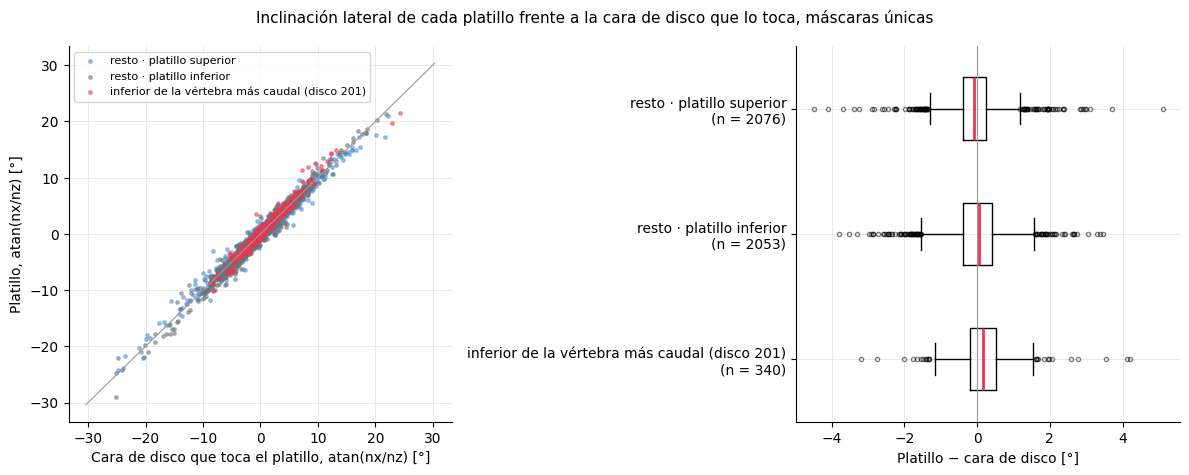

In [8]:
# 8. Cada platillo frente a la cara de disco que lo toca
def bland_altman(df, col):
    d = df[col].dropna()
    if len(d) < 3:
        return {"n": len(d)}
    rng = np.random.default_rng(SEMILLA)
    grupos = [g.values for _, g in df.loc[d.index].groupby("estudio")[col]]
    sesgos = [np.mean(np.concatenate([grupos[k] for k in rng.integers(0, len(grupos), len(grupos))]))
              for _ in range(B_BOOTSTRAP)]           # se remuestrean estudios completos, no series ni platillos
    sesgo, de = d.mean(), d.std(ddof=1)
    return {"n": len(d), "estudios": len(grupos), "sesgo": sesgo,
            "ic95_sesgo": f"{np.percentile(sesgos, 2.5):.2f} a {np.percentile(sesgos, 97.5):.2f}",
            "lim_inf": sesgo - 1.96 * de, "lim_sup": sesgo + 1.96 * de,
            "mediana_abs": d.abs().median(), "p90_abs": d.abs().quantile(0.9), "max_abs": d.abs().max()}

GRUPOS = ["inferior de la vértebra más caudal (disco 201)", "resto · platillo inferior", "resto · platillo superior"]
validos["grupo"] = np.where((validos["platillo"] == "inferior") & (validos["disco_vecino"] == 201), GRUPOS[0],
                            np.where(validos["platillo"] == "inferior", GRUPOS[1], GRUPOS[2]))
filas = []
for grupo in GRUPOS:
    g = validos[validos["grupo"] == grupo]
    for secuencia in ("todas", "t1", "t2", "t2_SPACE"):
        gg = g if secuencia == "todas" else g[g["secuencia"] == secuencia]
        filas.append({"grupo": grupo, "secuencia": secuencia, **bland_altman(gg, "dif_platillo_menos_disco"),
                      "mediana_abs_sagital_platillo": gg["inclinacion_sagital"].abs().median(),
                      "mediana_abs_sagital_disco": gg["sagital_cara_disco"].abs().median()})
acuerdo_caras = pd.DataFrame(filas)
acuerdo_caras.to_csv(DIR_SALIDA / "acuerdo_platillo_vs_cara.csv", index=False)
display(acuerdo_caras.round(2))

colores = dict(zip(GRUPOS, ("#e8384f", "#6c757d", "#4a90d9")))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
lim = np.nanmax(np.abs(validos[["angulo_coronal", "angulo_cara_disco"]].to_numpy())) * 1.05
ax.plot([-lim, lim], [-lim, lim], color="#999999", lw=0.8)
for grupo in GRUPOS[::-1]:
    g = validos[validos["grupo"] == grupo]
    ax.scatter(g["angulo_cara_disco"], g["angulo_coronal"], s=6, alpha=0.5, color=colores[grupo], label=grupo)
ax.set_xlabel("Cara de disco que toca el platillo, atan(nx/nz) [°]")
ax.set_ylabel("Platillo, atan(nx/nz) [°]")
ax.legend(fontsize=8)
ax = axes[1]
ax.boxplot([validos.loc[validos["grupo"] == g, "dif_platillo_menos_disco"] for g in GRUPOS], vert=False, widths=0.5,
           tick_labels=[f"{g}\n(n = {(validos['grupo'] == g).sum()})" for g in GRUPOS],
           medianprops={"color": "#e8384f", "lw": 2}, flierprops={"ms": 3, "alpha": 0.5})
ax.axvline(0, color="#999999", lw=0.8)
ax.set_xlabel("Platillo − cara de disco [°]")
for a in axes:
    a.grid(color="#e5e5e5", lw=0.6); a.set_axisbelow(True)
    for lado in ("top", "right"):
        a.spines[lado].set_visible(False)
fig.suptitle("Inclinación lateral de cada platillo frente a la cara de disco que lo toca, máscaras únicas", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_platillo_vs_cara.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la tabla y las gráficas.** Cada fila resume, para un grupo de platillos y una secuencia, la diferencia entre la inclinación lateral del platillo y la de la cara de disco que toca. Se muestran el sesgo y su intervalo de confianza, los límites de acuerdo, la mediana de la diferencia absoluta y su percentil 90. Las dos últimas columnas presentan la inclinación sagital mediana (en valor absoluto) del platillo y de la cara de disco. En la gráfica de la izquierda, cada punto representa un platillo: los puntos próximos a la diagonal indican inclinaciones similares. A la derecha, los diagramas de caja resumen las diferencias de cada grupo.

**Resultados.** Las dos medidas son muy parecidas: la correlación entre las inclinaciones es de 0,99, la mitad de las diferencias es de 0,4° o menos y los límites de acuerdo rondan ±1,4° en los tres grupos. Los sesgos son pequeños: 0,01° en los platillos inferiores fuera del extremo caudal, −0,07° en los superiores y 0,19° en el platillo inferior de V1 frente a la cara superior del disco 201 (IC del 95 %: 0,07° a 0,31°). La mayor diferencia observada es de 5,1°, en el platillo superior de V3 de `186_t1`.

Las inclinaciones sagitales también son similares: las medianas son de 27° frente a 28° en el extremo caudal y de aproximadamente 8° en los demás platillos. El patrón es parecido en las tres secuencias.

Este acuerdo debe interpretarse con cautela. Como la condición de contacto selecciona el platillo y la cara de disco que forman una misma interfaz, es esperable que sus inclinaciones sean cercanas. Aun así, las superficies no se ajustan exactamente del mismo modo: el script utiliza la mitad completa del disco, incluido su borde lateral, mientras que aquí se selecciona únicamente la superficie del platillo que está en contacto con el disco.

## Ángulo de Cobb por platillos frente a las reglas basadas en caras de disco

La celda 9 compara, para cada máscara, el ángulo calculado a partir de los platillos con los obtenidos mediante las dos reglas basadas en caras de disco. Para la regla del artículo también se comprueba en cuántas máscaras el par de vértebras elegido por los platillos corresponde al mismo par de discos.

Esta equivalencia no puede calcularse de la misma manera para la regla del script, porque esta utiliza las caras opuestas de cada disco.

,comparacion,secuencia,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs,mismo_par_pct,una_sola_vertebra
0,platillos − articulo,todas,340,218,0.26,0.13 a 0.40,-1.68,2.20,0.59,1.55,4.92,62.94,15
1,platillos − articulo,t1,196,196,0.19,0.04 a 0.33,-1.82,2.19,0.60,1.51,4.51,64.80,9
2,platillos − articulo,t2,103,103,0.40,0.25 a 0.57,-1.24,2.03,0.50,1.25,4.92,62.14,3
3,platillos − articulo,t2_SPACE,41,41,0.28,-0.07 a 0.65,-2.01,2.57,0.61,1.87,3.43,56.10,3
4,platillos − script,todas,340,218,-0.13,-0.38 a 0.08,-3.53,3.27,0.95,2.46,10.97,NaN,15
5,platillos − script,t1,196,196,-0.12,-0.40 a 0.12,-3.71,3.47,1.04,2.72,10.86,NaN,9
6,platillos − script,t2,103,103,-0.03,-0.27 a 0.22,-2.55,2.49,0.78,2.03,4.43,NaN,3
7,platillos − script,t2_SPACE,41,41,-0.40,-1.13 a 0.20,-4.70,3.90,0.68,2.63,10.97,NaN,3


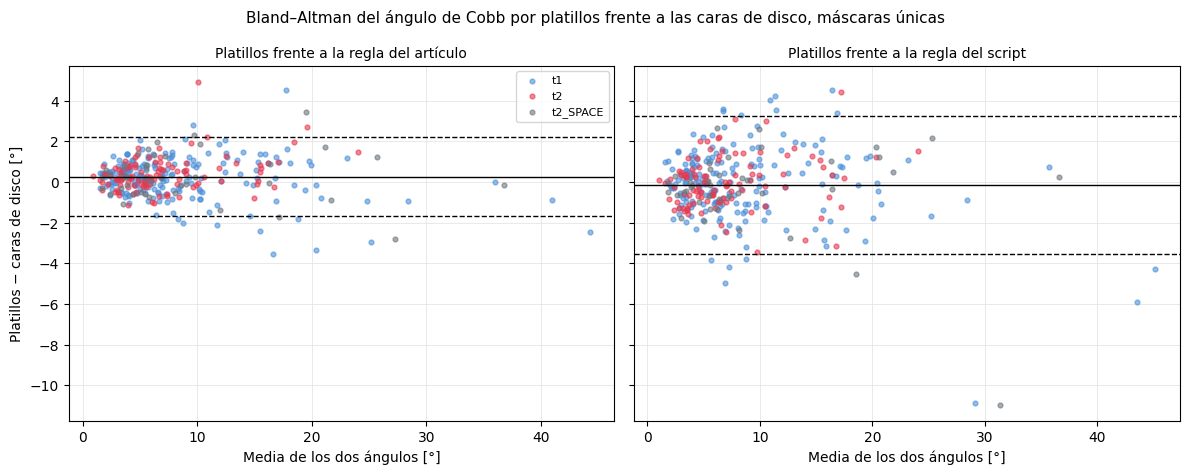

Estudio 162:
       serie  cobb_platillos  vertebra_inf  vertebra_sup  cobb_articulo  disco_inf_articulo  disco_sup_articulo  cobb_script  disco_inf_script  disco_sup_script
      162_t1           23.71             1             3          26.63                 201                 204        34.57               201               204
162_t2_SPACE           25.90             1             3          28.72                 201                 204        36.87               201               204


In [9]:
# 9. Cobb por platillos frente a las dos reglas de caras de disco
filas = []
for regla in ("articulo", "script"):
    for secuencia in ("todas", "t1", "t2", "t2_SPACE"):
        g = por_serie if secuencia == "todas" else por_serie[por_serie["secuencia"] == secuencia]
        fila = {"comparacion": f"platillos − {regla}", "secuencia": secuencia, **bland_altman(g, f"dif_vs_{regla}")}
        if regla == "articulo":
            fila["mismo_par_pct"] = 100 * g["mismo_par_articulo"].mean()
        fila["una_sola_vertebra"] = int(g["una_sola_vertebra"].sum())
        filas.append(fila)
acuerdo_cobb = pd.DataFrame(filas)
acuerdo_cobb.to_csv(DIR_SALIDA / "acuerdo_cobb_platillos_vs_discos.csv", index=False)
display(acuerdo_cobb.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, regla, titulo in zip(axes, ("articulo", "script"), ("regla del artículo", "regla del script")):
    media = (por_serie["cobb_platillos"] + por_serie[f"cobb_{regla}"]) / 2
    for secuencia, color in (("t1", "#4a90d9"), ("t2", "#e8384f"), ("t2_SPACE", "#6c757d")):
        m = por_serie["secuencia"] == secuencia
        ax.scatter(media[m], por_serie.loc[m, f"dif_vs_{regla}"], s=12, alpha=0.6, color=color, label=secuencia)
    r = bland_altman(por_serie, f"dif_vs_{regla}")
    ax.axhline(r["sesgo"], color="k", lw=1)
    for lim in (r["lim_inf"], r["lim_sup"]):
        ax.axhline(lim, color="k", lw=1, ls="--")
    ax.set_title(f"Platillos frente a la {titulo}", fontsize=10)
    ax.set_xlabel("Media de los dos ángulos [°]")
    ax.grid(color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("Platillos − caras de disco [°]")
axes[0].legend(fontsize=8)
fig.suptitle("Bland–Altman del ángulo de Cobb por platillos frente a las caras de disco, máscaras únicas", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "bland_altman_platillos_vs_discos.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

print("Estudio 162:")
print(por_serie[por_serie["estudio"] == 162][["serie", "cobb_platillos", "vertebra_inf", "vertebra_sup",
                                              "cobb_articulo", "disco_inf_articulo", "disco_sup_articulo",
                                              "cobb_script", "disco_inf_script", "disco_sup_script"]].round(2).to_string(index=False))

**Cómo leer la tabla y las gráficas.** Cada fila compara el ángulo por platillos con una de las dos reglas de caras de disco, en todas las máscaras o en una sola secuencia. Se muestran el sesgo y su intervalo de confianza, los límites de acuerdo, la mediana de la diferencia absoluta y su percentil 90. `mismo_par_pct` indica en qué porcentaje de las máscaras el par de vértebras de los platillos corresponde al par de discos de la regla del artículo, y `una_sola_vertebra` cuenta las máscaras en las que el máximo se forma con los dos platillos de una misma vértebra. En las gráficas, cada punto es una máscara: el eje horizontal es la media de los dos ángulos y el vertical su diferencia; la línea continua marca el sesgo y las discontinuas, los límites de acuerdo. Debajo se imprimen los ángulos y los pares del estudio 162.

**Resultados.** El ángulo por platillos es muy parecido al obtenido con la regla del artículo: en promedio es 0,26° mayor (IC del 95 %: 0,13° a 0,40°), con límites de acuerdo de −1,7° a 2,2°. La diferencia supera los 2° en 18 máscaras y los 3° en cinco. Ambos métodos seleccionan el mismo par de discos en el 63 % de las máscaras, una proporción similar a la coincidencia observada entre segmentadores en el cuaderno 05.

Frente a la regla del script, el sesgo medio es prácticamente nulo (−0,13°), pero los límites de acuerdo son más amplios (−3,5° a 3,3°). Esto concuerda con la diferencia entre las reglas: la del script utiliza las caras opuestas de cada disco.

En 15 máscaras, el ángulo por platillos se define con dos platillos de una misma vértebra. En el estudio 162, los ángulos por platillos son 23,7° y 25,9°; quedan algo por debajo de los de la regla del artículo (26,6° y 28,7°) y más lejos de los de la regla del script (34,6° y 36,9°). Por tanto, el ángulo elevado de ese estudio se mantiene al medir los platillos. La diferencia adicional de la regla del script procede de la cara inferior del disco 201, que contacta con el sacro.

In [10]:
# 9b. Misma columna, otra secuencia: T1 frente a T2 del mismo estudio con cada forma de medir
pares = (por_serie[por_serie["secuencia"].isin(["t1", "t2"])]
         .pivot_table(index="estudio", columns="secuencia", values=["cobb_platillos", "cobb_articulo", "cobb_script"])
         .dropna())
filas = []
for medida in ("cobb_platillos", "cobb_articulo", "cobb_script"):
    df = pd.DataFrame({"estudio": pares.index, "dif_t1_t2": (pares[(medida, "t1")] - pares[(medida, "t2")]).to_numpy()})
    filas.append({"medida": medida, **bland_altman(df, "dif_t1_t2")})
t1_t2 = pd.DataFrame(filas)
t1_t2.to_csv(DIR_SALIDA / "acuerdo_t1_t2_por_medida.csv", index=False)
display(t1_t2.round(2))

,medida,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs
0,cobb_platillos,83,83,0.05,-0.13 a 0.23,-1.57,1.66,0.40,1.31,2.96
1,cobb_articulo,83,83,0.03,-0.13 a 0.19,-1.41,1.48,0.29,1.00,2.75
2,cobb_script,83,83,-0.12,-0.39 a 0.12,-2.42,2.18,0.48,1.10,7.43


**Cómo leer la tabla.** Cada fila compara los ángulos de una misma forma de medición entre estudios que cuentan con máscaras manuales distintas para T1 y T2. Como el análisis utiliza solo máscaras únicas, se excluyen automáticamente los estudios cuyas secuencias T1 y T2 comparten la misma máscara.

**Resultados.** En los 83 estudios con máscaras distintas, el cambio del ángulo por platillos entre T1 y T2 presenta límites de acuerdo de −1,6° a 1,7°. El resultado es similar al de la regla del artículo (−1,4° a 1,5°) y más estrecho que el de la regla del script (−2,4° a 2,2°). El sesgo es prácticamente nulo en los tres métodos.

En este conjunto, la medición por platillos es tan reproducible entre secuencias como la medición de las caras de disco con la regla del artículo. En la primera versión del método, antes de añadir la condición de contacto, los límites eran más amplios: de −3,1° a 3,4°.

In [19]:
# 9c. ¿Explica el ruido el sesgo? Ruido simulado sobre las caras de disco (regla del artículo)
N_SIM = 200
SIGMAS = (0.5, 1.0, 1.5, round(float(validos["dif_platillo_menos_disco"].std()), 2))   # el último: desviación platillo − cara

def maximo_articulo(inf, sup):
    '''Máximo de |sup[a] − inf[b]| con a < b para uno o varios juegos de ángulos (última dimensión = discos en orden).
    Devuelve el máximo y los índices (a, b) del par, con el mismo desempate que el script (primer máximo en orden).'''
    dif = np.abs(sup[..., :, None] - inf[..., None, :])                  # [..., a, b]
    n = dif.shape[-1]
    dif = np.where(np.triu(np.ones((n, n), bool), k=1), dif, -1.0)       # solo a < b
    plano = dif.reshape(*dif.shape[:-2], n * n)
    k = plano.argmax(axis=-1)
    return plano.max(axis=-1), k // n, k % n

rng = np.random.default_rng(SEMILLA)
filas = []
for s, caras in planos_disco[planos_disco["serie"].isin(unicas)].groupby("serie"):
    inf = caras[caras["cara"] == "inferior"].set_index("disco")["angulo_coronal_script"].sort_index()
    sup = caras[caras["cara"] == "superior"].set_index("disco")["angulo_coronal_script"].reindex(inf.index)
    if len(inf) < 2:
        continue
    base, a0, b0 = maximo_articulo(inf.to_numpy(), sup.to_numpy())
    for sigma in SIGMAS:
        ruido_inf = inf.to_numpy() + rng.normal(0, sigma, (N_SIM, len(inf)))
        ruido_sup = sup.to_numpy() + rng.normal(0, sigma, (N_SIM, len(inf)))
        m, a, b = maximo_articulo(ruido_inf, ruido_sup)
        filas.append({"serie": s, "sigma": sigma, "aumento_medio": float(np.mean(m - base)),
                      "cambia_par_pct": float(100 * np.mean((a != a0) | (b != b0)))})
simulacion = pd.DataFrame(filas).join(inventario[["estudio"]], on="serie")
resumen_sim = (simulacion.groupby("sigma")[["aumento_medio", "cambia_par_pct"]].mean()
               .rename(columns={"aumento_medio": "aumento_medio_del_maximo", "cambia_par_pct": "par_distinto_pct"}))
resumen_sim["sesgo_observado_platillos"] = por_serie["dif_vs_articulo"].mean()
resumen_sim["par_distinto_observado_pct"] = 100 * (1 - por_serie["mismo_par_articulo"].mean())
resumen_sim.to_csv(DIR_SALIDA / "simulacion_ruido.csv")
print(f"{N_SIM} repeticiones por máscara y por sigma; ruido normal independiente en cada cara de disco")
display(resumen_sim.round(2))

200 repeticiones por máscara y por sigma; ruido normal independiente en cada cara de disco


,aumento_medio_del_maximo,par_distinto_pct,sesgo_observado_platillos,par_distinto_observado_pct
sigma,,,,
0.5,0.20,34.14,0.26,37.06
0.7,0.37,42.43,0.26,37.06
1.0,0.70,52.67,0.26,37.06
1.5,1.42,63.99,0.26,37.06


**Cómo leer la tabla.** Cada fila representa un nivel de ruido simulado ($\sigma$, en grados). El ruido se añade de forma independiente a cada cara de disco de las 340 máscaras; después, se vuelve a aplicar la regla del artículo 200 veces por máscara. `aumento_medio_del_maximo` indica cuánto aumenta el ángulo promedio y `par_distinto_pct` señala en qué porcentaje de las repeticiones cambia el par seleccionado. Las dos últimas columnas no son simuladas: repiten en todas las filas lo observado al comparar los platillos con la regla del artículo (el sesgo medio y el porcentaje de máscaras con otro par), para tenerlo como referencia. Uno de los niveles de ruido, 0,7°, corresponde a la desviación estándar de las diferencias observadas entre cada platillo y su cara de disco.

**Resultados.** Con un ruido de 0,7° por cara, la regla del artículo aumentaría el ángulo en promedio 0,37° y cambiaría el par seleccionado en el 42,43 % de las repeticiones. Lo observado al medir en los platillos queda algo por debajo: un sesgo de 0,26° frente a la regla del artículo y un par distinto en el 37 % de las máscaras.

Esto sugiere que el pequeño sesgo restante y la coincidencia incompleta entre niveles pueden explicarse por el ruido de medición. De hecho, los 0,7° incluyen la variabilidad de ambas mediciones, no solo la de los platillos. La simulación también ayuda a interpretar la primera versión del método: con un ruido de 1,5° por platillo, el máximo aumentaba aproximadamente 1,4°, cerca del sesgo de 1,5° observado antes de incorporar la condición de contacto. Para una futura implementación automática, conviene tener presente que incluso un ruido de 0,5° hace que el par seleccionado cambie en cerca de un tercio de las repeticiones.

Pares a menos de 1° del máximo, por máscara:
  articulo : mediana 3 · un solo candidato en 89 de 340 · margen mediano entre el primero y el segundo 0.46°
  platillos: mediana 2 · un solo candidato en 94 de 340 · margen mediano entre el primero y el segundo 0.52°

Mismo par que la regla del artículo: 89 % cuando esa regla tiene un solo candidato (89 máscaras) y 54 % cuando tiene varios (251)
El par de los platillos está entre los candidatos de la regla del artículo en 94 % de las máscaras, y el del artículo entre los candidatos de los platillos en 93 %


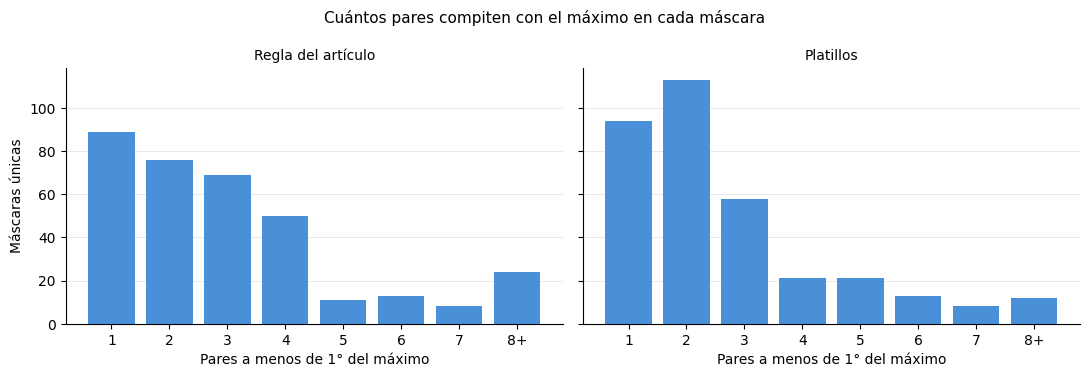

In [12]:
# 9d. Pares candidatos: cuántos pares quedan cerca del máximo en cada máscara
TOL_CANDIDATO = 1.0   # grados por debajo del máximo para contar un par como candidato

def pares_articulo(caras):
    inf = caras[caras["cara"] == "inferior"].set_index("disco")["angulo_coronal_script"]
    sup = caras[caras["cara"] == "superior"].set_index("disco")["angulo_coronal_script"]
    labels = sorted(int(l) for l in inf.index)
    return {(a, b): abs(sup[a] - inf[b]) for i, a in enumerate(labels) for b in labels[i + 1:]}

def pares_platillos(g):
    '''Pares de platillos expresados como el par de discos equivalente (disco bajo L, disco sobre U).'''
    inf = g[g["platillo"] == "inferior"].set_index("vertebra")
    sup = g[g["platillo"] == "superior"].set_index("vertebra")
    return {(int(inf.loc[L, "disco_vecino"]), int(sup.loc[U, "disco_vecino"])): abs(sup.loc[U, "angulo_coronal"] - inf.loc[L, "angulo_coronal"])
            for L in inf.index for U in sup.index if L <= U}

def candidatos(pares):
    ordenados = sorted(pares.values(), reverse=True)
    maximo = ordenados[0]
    return {"n_candidatos": sum(v >= maximo - TOL_CANDIDATO for v in ordenados),
            "margen_segundo": maximo - ordenados[1] if len(ordenados) > 1 else np.nan,
            "candidatos": {p for p, v in pares.items() if v >= maximo - TOL_CANDIDATO}}

filas = []
for s, g in validos.groupby("serie"):
    art = candidatos(pares_articulo(planos_disco[planos_disco["serie"] == s]))
    pla = candidatos(pares_platillos(g))
    fila = por_serie.set_index("serie").loc[s]
    par_pla = (fila["disco_inf_equivalente"], fila["disco_sup_equivalente"])
    par_art = (fila["disco_inf_articulo"], fila["disco_sup_articulo"])
    filas.append({"serie": s, "estudio": fila["estudio"],
                  "n_candidatos_articulo": art["n_candidatos"], "margen_segundo_articulo": art["margen_segundo"],
                  "n_candidatos_platillos": pla["n_candidatos"], "margen_segundo_platillos": pla["margen_segundo"],
                  "mismo_par_articulo": fila["mismo_par_articulo"],
                  "par_platillos_entre_candidatos_articulo": par_pla in art["candidatos"],
                  "par_articulo_entre_candidatos_platillos": par_art in pla["candidatos"]})
cand = pd.DataFrame(filas)
cand.to_csv(DIR_SALIDA / "pares_candidatos.csv", index=False)

print(f"Pares a menos de {TOL_CANDIDATO:g}° del máximo, por máscara:")
for medida in ("articulo", "platillos"):
    n = cand[f"n_candidatos_{medida}"]
    print(f"  {medida:9s}: mediana {n.median():.0f} · un solo candidato en {(n == 1).sum()} de {len(n)} · "
          f"margen mediano entre el primero y el segundo {cand[f'margen_segundo_{medida}'].median():.2f}°")
unico = cand["n_candidatos_articulo"] == 1
print(f"\nMismo par que la regla del artículo: {100 * cand.loc[unico, 'mismo_par_articulo'].mean():.0f} % cuando esa regla "
      f"tiene un solo candidato ({unico.sum()} máscaras) y {100 * cand.loc[~unico, 'mismo_par_articulo'].mean():.0f} % "
      f"cuando tiene varios ({(~unico).sum()})")
print(f"El par de los platillos está entre los candidatos de la regla del artículo en "
      f"{100 * cand['par_platillos_entre_candidatos_articulo'].mean():.0f} % de las máscaras, y el del artículo entre los "
      f"candidatos de los platillos en {100 * cand['par_articulo_entre_candidatos_platillos'].mean():.0f} %")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, medida, titulo in zip(axes, ("articulo", "platillos"), ("Regla del artículo", "Platillos")):
    n = cand[f"n_candidatos_{medida}"].clip(upper=8)
    ax.bar(*np.unique(n, return_counts=True), color="#4a90d9")
    ax.set_xticks(range(1, 9), [str(i) for i in range(1, 8)] + ["8+"])
    ax.set_title(titulo, fontsize=10); ax.set_xlabel(f"Pares a menos de {TOL_CANDIDATO:g}° del máximo")
    ax.grid(axis="y", color="#e5e5e5", lw=0.6); ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
axes[0].set_ylabel("Máscaras únicas")
fig.suptitle("Cuántos pares compiten con el máximo en cada máscara", fontsize=11)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "figura_pares_candidatos.png", dpi=130, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida y la gráfica.** Para cada máscara se cuentan los pares cuyo ángulo queda a menos de 1° del máximo, tanto con la regla del artículo como con la medición por platillos (expresada mediante su par equivalente de discos). También se calcula la diferencia entre el primer y el segundo candidato y se compara la coincidencia de los pares elegidos cuando hay uno o varios candidatos. Las barras muestran cuántas máscaras tienen uno, dos, tres o más candidatos.

**Resultados.** Con la regla del artículo, solo 89 de las 340 máscaras tienen un único par a menos de 1° del máximo. La mediana es de tres candidatos y la diferencia mediana entre el primero y el segundo es de 0,46°. Con los platillos, 94 máscaras tienen un solo candidato y la diferencia mediana es de 0,52°.

Cuando la regla del artículo tiene un único candidato, los platillos eligen el mismo par en el 89 % de las máscaras; cuando hay varios, la coincidencia baja al 54 %. Sin embargo, el par elegido por los platillos está entre los candidatos de la regla del artículo en el 94 % de las máscaras, y el par del artículo está entre los candidatos de los platillos en el 93 %.

Por tanto, muchos pares diferentes son, en la práctica, alternativas con ángulos casi iguales y no desacuerdos importantes. Para una futura herramienta automática, mostrar un solo par podría dar una falsa impresión de certeza: tres de cada cuatro máscaras tienen varios candidatos cercanos al máximo. Sería más informativo presentar el ángulo junto con los pares candidatos.

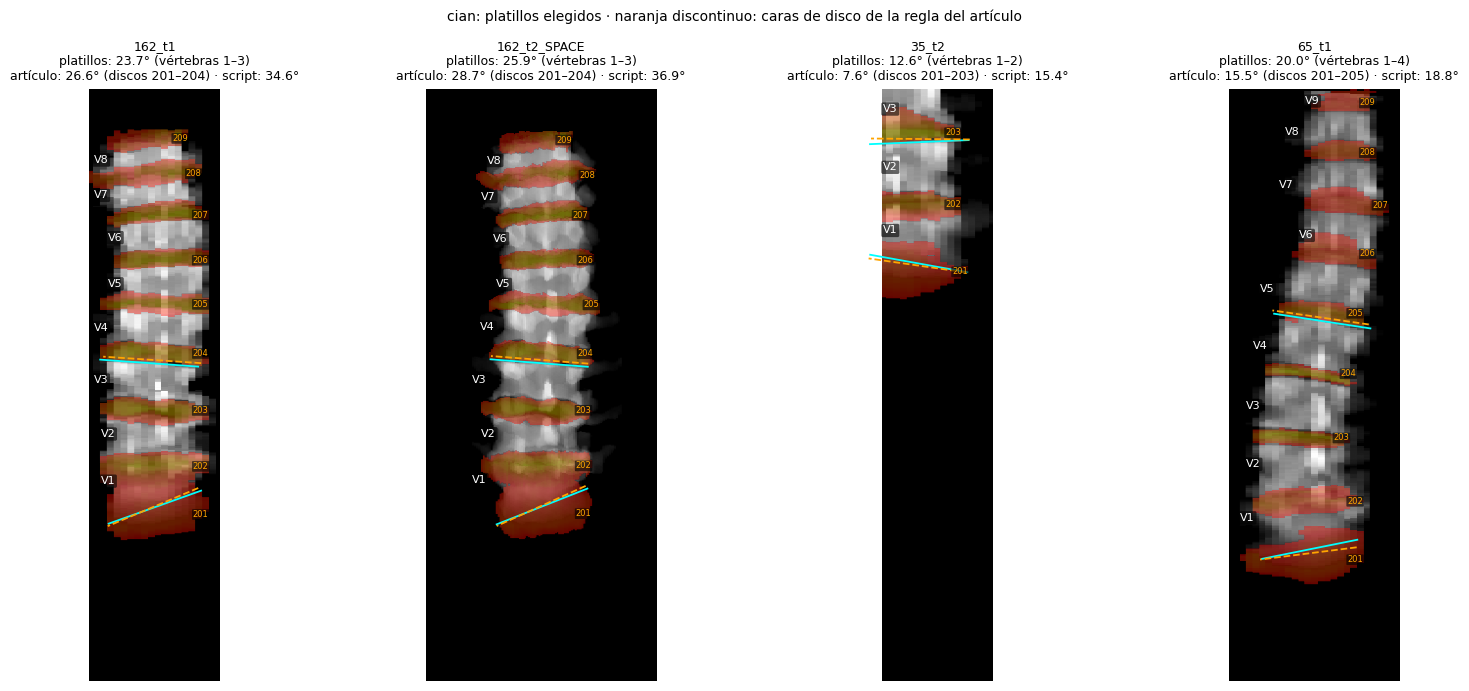

In [13]:
# 10. Casos: las dos máscaras del estudio 162 y las dos con mayor diferencia frente a la regla del artículo
N_CASOS_EXTREMOS = 2   # @param {type:"integer"}
extremos = (por_serie[por_serie["estudio"] != 162]
            .assign(abs_dif=lambda d: d["dif_vs_articulo"].abs())
            .nlargest(N_CASOS_EXTREMOS, "abs_dif")["serie"].tolist())
CASOS = [s for s in ("162_t1", "162_t2_SPACE") if s in set(por_serie["serie"])] + extremos

fig, axes = plt.subplots(1, len(CASOS), figsize=(4.2 * len(CASOS), 7), squeeze=False)
for ax, s in zip(axes[0], CASOS):
    m = en_espacio_del_script(DIR_LOCAL / f"{s}.mha")
    ax.imshow(((m > 0) & (m < CANAL)).sum(1).T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_equal((m > 200).sum(1).T, 0), cmap="autumn", alpha=0.4, origin="lower")
    fila = por_serie.set_index("serie").loc[s]
    g = validos[validos["serie"] == s].set_index(["vertebra", "platillo"])
    if not np.isnan(fila["cobb_platillos"]):
        dibujar_plano(ax, g.loc[(int(fila["vertebra_inf"]), "inferior")], "cyan")
        dibujar_plano(ax, g.loc[(int(fila["vertebra_sup"]), "superior")], "cyan")
    c = planos_disco[planos_disco["serie"] == s].set_index(["disco", "cara"])
    dibujar_plano(ax, c.loc[(int(fila["disco_inf_articulo"]), "superior")], "orange", ls="--")
    dibujar_plano(ax, c.loc[(int(fila["disco_sup_articulo"]), "inferior")], "orange", ls="--")
    ax.invert_xaxis()
    rotular_vertebras(ax, m, "coronal", discos=True)
    ax.set_title(f"{s}\nplatillos: {fila['cobb_platillos']:.1f}° (vértebras {fila['vertebra_inf']:.0f}–{fila['vertebra_sup']:.0f})\n"
                 f"artículo: {fila['cobb_articulo']:.1f}° (discos {fila['disco_inf_articulo']:.0f}–{fila['disco_sup_articulo']:.0f})"
                 f" · script: {fila['cobb_script']:.1f}°", fontsize=9)
    ax.axis("off")
fig.suptitle("cian: platillos elegidos · naranja discontinuo: caras de disco de la regla del artículo", fontsize=10)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "panel_casos.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer el panel.** Cada imagen muestra la proyección coronal utilizada por el script, con las vértebras en gris, los discos en color y la cabeza orientada hacia arriba. Las líneas cian representan los dos platillos que definen el ángulo por platillos; las líneas naranjas discontinuas muestran las dos caras de disco seleccionadas por la regla del artículo. Los dos primeros casos corresponden al estudio 162. Los siguientes son las máscaras con mayores diferencias frente a la regla del artículo; la selección depende del valor de `N_CASOS_EXTREMOS`.

**Resultados.** En las dos máscaras del estudio 162, ambos métodos eligen los mismos niveles (V1 a V3, equivalentes a los discos 201 a 204). La diferencia, cercana a 3°, se debe a que el platillo inferior de V1 tiene menos inclinación que la cara superior del disco 201.

Las dos máscaras con mayor diferencia frente a la regla del artículo también comparten los niveles seleccionados. En `35_t2`, cuyo campo de visión solo incluye tres discos, el ángulo por platillos es de 12,6°, frente a 7,6° con la regla del artículo. Los dos platillos seleccionados tienen entre 2° y 3° más inclinación que las caras de disco correspondientes. En `65_t1`, la diferencia (20,0° frente a 15,5°) se concentra en el platillo inferior de V1, cuya inclinación supera en 4,1° a la cara superior del disco 201.

Este último es el mismo nivel en el que el cuaderno 05 detectó diferencias entre TotalSpineSeg y las otras segmentaciones en el estudio 65. En conjunto, ambos análisis indican que el extremo caudal de la columna es sensible a la superficie que se elija para medir.

Las etiquetas V1, V2… siguen la numeración de SPIDER desde la vértebra más caudal; no son niveles anatómicos (V1 no equivale necesariamente a L5). Los números naranjas identifican los discos.

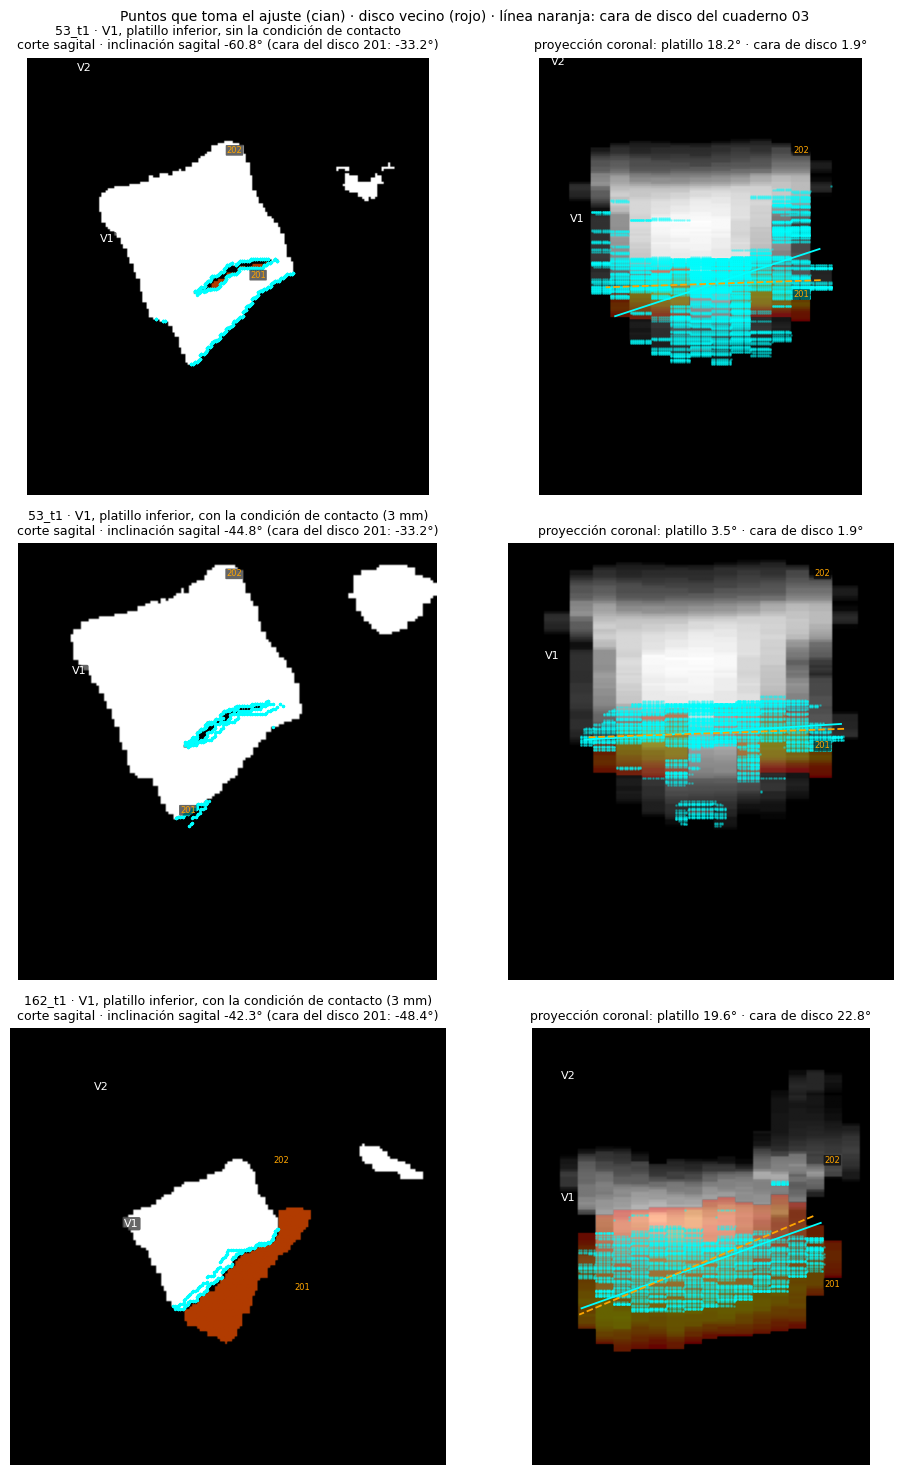

In [14]:
# 10b. El fallo de la primera versión y su corrección: puntos del platillo inferior de la vértebra 1 en 53_t1
# (serie, vértebra, platillo, distancia máxima al disco en mm; None = sin esa condición, como en la primera versión)
CASOS_FALLO = [("53_t1", 1, "inferior", None), ("53_t1", 1, "inferior", DIST_MAX_DISCO_MM), ("162_t1", 1, "inferior", DIST_MAX_DISCO_MM)]

def puntos_del_platillo(mascara, k, cara, disco_abajo, disco_arriba, dist_max):
    "Repite el ajuste de la celda 4 para una vértebra y devuelve el cuerpo, los puntos que entraron al ajuste y el plano."
    signo = signo_anterior(mascara)
    borde = borde_del_canal(mascara, signo)
    cajas = ndimage.find_objects(mascara.astype(np.int32))
    cuerpo, desp = cuerpo_vertebral(mascara, k, cajas[k - 1], borde, signo)
    centro = np.argwhere(cuerpo).mean(axis=0) + desp
    etiqueta = lambda d: None if d is None or pd.isna(d) else int(d)
    c_disco = lambda d: None if etiqueta(d) is None else np.argwhere(mascara == etiqueta(d)).mean(axis=0)
    discos = {"superior": etiqueta(disco_arriba), "inferior": etiqueta(disco_abajo)}
    res, puntos = ajuste_de_vertebra(mascara, cuerpo, desp, centro, c_disco(disco_abajo), c_disco(disco_arriba), discos,
                                     devolver_puntos=True, dist_max=dist_max)
    return cuerpo, desp, puntos[cara], res[cara]

fig, axes = plt.subplots(len(CASOS_FALLO), 2, figsize=(10, 5 * len(CASOS_FALLO)), squeeze=False)
for fila_ax, (s, k, cara, dist_max) in zip(axes, CASOS_FALLO):
    m = en_espacio_del_script(DIR_LOCAL / f"{s}.mha")
    vecinos = plat[(plat["serie"] == s) & (plat["vertebra"] == k)].set_index("platillo")["disco_vecino"]
    cuerpo, desp, puntos, plano = puntos_del_platillo(m, k, cara, vecinos.get("inferior"), vecinos.get("superior"), dist_max)
    disco = int(vecinos[cara])
    cara_disco = planos_disco[(planos_disco["serie"] == s) & (planos_disco["disco"] == disco)
                              & (planos_disco["cara"] == ("superior" if cara == "inferior" else "inferior"))].iloc[0]
    version = "sin la condición de contacto" if dist_max is None else f"con la condición de contacto ({dist_max:g} mm)"
    zona = slice(max(int(puntos[:, 2].min()) - 60, 0), int(puntos[:, 2].max()) + 60)
    xc = int(round(puntos[:, 0].mean()))
    # izquierda: corte sagital por el centro de los puntos
    ax = fila_ax[0]
    ax.imshow((m[xc] == k).T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_equal((m[xc] == disco).T, 0), cmap="autumn", vmin=0, vmax=3, alpha=0.7, origin="lower")
    cerca = np.abs(puntos[:, 0] - xc) < 3
    ax.scatter(puntos[cerca, 1], puntos[cerca, 2], s=2, color="cyan")
    rotular_vertebras(ax, m, "sagital", x_corte=xc, discos=True)
    ax.set_ylim(zona.start, zona.stop)
    ax.set_xlim(puntos[:, 1].min() - 60, puntos[:, 1].max() + 60)
    ax.set_title(f"{s} · V{k}, platillo {cara}, {version}\ncorte sagital · inclinación sagital "
                 f"{plano['inclinacion_sagital']:.1f}° (cara del disco {disco}: {cara_disco['inclinacion_sagital']:.1f}°)", fontsize=9)
    ax.axis("off")
    # derecha: proyección coronal del cuerpo con todos los puntos
    ax = fila_ax[1]
    proy = np.zeros(m.shape[::2], float)
    proy[desp[0]:desp[0] + cuerpo.shape[0], desp[2]:desp[2] + cuerpo.shape[2]] = cuerpo.sum(1)
    ax.imshow(proy.T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_equal((m == disco).sum(1).T, 0), cmap="autumn", alpha=0.4, origin="lower")
    ax.scatter(puntos[:, 0], puntos[:, 2], s=1, color="cyan", alpha=0.3)
    dibujar_plano(ax, plano, "cyan")
    dibujar_plano(ax, cara_disco, "orange", ls="--")
    ax.set_ylim(zona.start, zona.stop)
    ax.invert_xaxis()
    rotular_vertebras(ax, m, "coronal", discos=True)
    ax.set_title(f"proyección coronal: platillo {plano['angulo_coronal']:.1f}° · cara de disco {cara_disco['angulo_coronal_script']:.1f}°",
                 fontsize=9)
    ax.axis("off")
fig.suptitle("Puntos que toma el ajuste (cian) · disco vecino (rojo) · línea naranja: cara de disco del cuaderno 03", fontsize=10)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "panel_fallo_53_t1.png", dpi=110, bbox_inches="tight")
plt.show()

**Cómo leer el panel.** Cada fila corresponde a un platillo. A la izquierda se muestra un corte sagital que atraviesa el centro de los puntos utilizados en el ajuste: la vértebra aparece en blanco, el disco vecino en rojo y los puntos seleccionados en cian. A la derecha se presenta la proyección coronal del cuerpo vertebral, con todos los puntos, el plano ajustado en cian y la cara de disco del cuaderno 03 en naranja.

La primera fila muestra `53_t1` sin la condición de contacto, tal como funcionaba la primera versión del método. La segunda muestra la misma vértebra después de aplicar la condición. La tercera presenta `162_t1` como referencia de un caso que ya funcionaba correctamente. Las etiquetas V1, V2… siguen la numeración de SPIDER desde la vértebra más caudal; no representan niveles anatómicos (V1 no equivale necesariamente a L5). Los números naranjas identifican los discos.

**Resultados.** En `53_t1`, la etiqueta V1 de la máscara manual rodea al disco 201: el disco aparece como una isla dentro de la región etiquetada como vértebra y, por debajo, todavía hay vóxeles asignados a V1. Sin la condición de contacto, el ajuste mezclaba dos superficies, la que contacta con el disco y el borde inferior del tejido, y producía un plano muy inclinado: 18,2°, frente a 1,9° en la cara de disco.

Al exigir el contacto con el disco, el ajuste se concentra en la superficie que lo rodea y la inclinación del plano baja a 3,5°. Como resultado, el ángulo por platillos de esa máscara pasa de 18,1° a 2,1°, frente a 1,8° con la regla del artículo. En `162_t1`, la condición apenas cambia el resultado, porque los puntos ya seguían una única superficie junto al disco.

Este análisis no permite determinar si la forma de la máscara de `53_t1` representa una variante anatómica (por ejemplo, una vértebra de transición) o si se debe a un detalle de la segmentación.



In [18]:
# 10c. Cuánto cambió el ángulo por platillos con la condición de contacto (frente a la primera corrida, guardada aparte)
DIR_VERSION_ANTERIOR = DIR_SALIDA / "version_sin_contacto"
if not (DIR_VERSION_ANTERIOR / "cobb_por_serie.csv").exists():
    print("No está la primera corrida en version_sin_contacto/ (se publica en el repositorio, dentro de esta misma carpeta de salidas); "
          "esta comparación se omite y el resto del cuaderno no la necesita.")
else:
    antes = pd.read_csv(DIR_VERSION_ANTERIOR / "cobb_por_serie.csv", dtype={"serie": str}).set_index("serie")
    ahora = por_serie.set_index("serie")
    cambio = ahora[["estudio", "secuencia"]].assign(
        cobb_sin_contacto=antes["cobb_platillos"], cobb_con_contacto=ahora["cobb_platillos"], cobb_articulo=ahora["cobb_articulo"],
        mismo_par=(antes["vertebra_inf"] == ahora["vertebra_inf"]) & (antes["vertebra_sup"] == ahora["vertebra_sup"]))
    cambio["cambio"] = cambio["cobb_con_contacto"] - cambio["cobb_sin_contacto"]
    cambio.reset_index().to_csv(DIR_SALIDA / "cambio_por_condicion_de_contacto.csv", index=False)

    filas = []
    for secuencia in ("todas", "t1", "t2", "t2_SPACE"):
        g = cambio if secuencia == "todas" else cambio[cambio["secuencia"] == secuencia]
        filas.append({"secuencia": secuencia, **bland_altman(g, "cambio"),
                      "bajan": int((g["cambio"] < -0.05).sum()), "suben": int((g["cambio"] > 0.05).sum()),
                      "mismo_par_pct": 100 * g["mismo_par"].mean()})
    resumen_cambio = pd.DataFrame(filas)
    display(resumen_cambio.round(2))
    print(f"Media del ángulo por platillos: {cambio['cobb_sin_contacto'].mean():.2f}° sin la condición, "
          f"{cambio['cobb_con_contacto'].mean():.2f}° con ella y {cambio['cobb_articulo'].mean():.2f}° con la regla del artículo")

    p_antes = pd.read_csv(DIR_VERSION_ANTERIOR / "platillo_vs_cara_de_disco.csv", dtype={"serie": str}).set_index(["serie", "vertebra", "platillo"])
    p_ahora = validos.set_index(["serie", "vertebra", "platillo"])
    d = (p_ahora["angulo_coronal"] - p_antes["angulo_coronal"]).dropna()
    print(f"Por platillo ({len(d)}): cambio medio {d.mean():.2f}°, cambio absoluto mediano {d.abs().median():.2f}° "
          f"(percentil 90: {d.abs().quantile(0.9):.2f}°) · |platillo − cara de disco| medio: "
          f"{p_antes['dif_platillo_menos_disco'].abs().mean():.2f}° antes y {p_ahora['dif_platillo_menos_disco'].abs().mean():.2f}° ahora")
    print("\nMáscaras que más cambiaron:")
    print(cambio.reindex(cambio["cambio"].abs().sort_values(ascending=False).index).head(8)
          [["cobb_sin_contacto", "cobb_con_contacto", "cobb_articulo", "cambio"]].round(2).to_string())

,secuencia,n,estudios,sesgo,ic95_sesgo,lim_inf,lim_sup,mediana_abs,p90_abs,max_abs,bajan,suben,mismo_par_pct
0,todas,340,218,-1.25,-1.54 a -0.98,-5.45,2.95,1.43,3.48,16.03,248,82,45.00
1,t1,196,196,-1.33,-1.69 a -1.02,-5.90,3.24,1.58,3.47,16.03,143,46,43.37
2,t2,103,103,-1.25,-1.62 a -0.85,-5.25,2.74,1.29,3.71,7.03,75,25,38.83
3,t2_SPACE,41,41,-0.83,-1.21 a -0.47,-3.31,1.65,1.22,2.49,4.01,30,11,68.29


Media del ángulo por platillos: 9.54° sin la condición, 8.29° con ella y 8.03° con la regla del artículo
Por platillo (4469): cambio medio 0.07°, cambio absoluto mediano 0.74° (percentil 90: 2.15°) · |platillo − cara de disco| medio: 1.10° antes y 0.49° ahora

Máscaras que más cambiaron:
        cobb_sin_contacto  cobb_con_contacto  cobb_articulo  cambio
serie                                                              
53_t1               18.12               2.09           1.84  -16.03
100_t1              16.58               8.15           8.59   -8.44
81_t1               14.17               6.56           7.22   -7.61
234_t1              31.13              23.69          22.49   -7.44
67_t1               14.11               6.79           5.86   -7.32
11_t1               14.39               7.32           7.21   -7.07
67_t2               14.51               7.48           5.81   -7.03
35_t2                5.59              12.56           7.64    6.97


**Cómo leer la tabla y la salida.** Cada fila resume, para una secuencia, cuánto cambió el ángulo por platillos al añadir la condición de contacto. El cambio se calcula como el resultado con la condición menos el resultado sin ella. La tabla incluye las mismas medidas descriptivas de las comparaciones anteriores, el número de máscaras en las que el ángulo bajó o subió y el porcentaje en el que se mantuvo el mismo par de vértebras.

Debajo se muestran las medias de las dos versiones y de la regla del artículo, el cambio observado en cada platillo y las máscaras con las variaciones más grandes. La primera ejecución se conserva en `version_sin_contacto/`; sus resultados no se utilizan en las demás celdas.

**Resultados.** Al incorporar la condición de contacto, el ángulo por platillos disminuyó en promedio 1,25° por máscara (IC del 95 %: 0,98° a 1,54°). La media pasó de 9,54° a 8,29°, acercándose a los 8,03° obtenidos con la regla del artículo. El ángulo bajó en 248 de las 340 máscaras y subió en 82. En la mitad de las máscaras, el cambio fue inferior a 1,4°; en 17, superó los 5°.

Al analizar cada platillo por separado, el cambio medio fue casi nulo (0,07°). No obstante, el desplazamiento mediano fue de 0,74° y la diferencia media respecto de la cara de disco se redujo de 1,10° a 0,49°. Esto indica que la condición no desplazó todos los platillos en una misma dirección, sino que redujo la variabilidad de los ajustes. Como el ángulo de Cobb se define mediante el máximo entre varios pares, reducir esa variabilidad también puede reducir el máximo, tal como anticipaba la celda 9c.

La mayoría de las máscaras con mayores cambios se acercó al valor de la regla del artículo; por ejemplo, `53_t1` pasó de 18,1° a 2,1°. La excepción más clara es `35_t2`, cuyo ángulo aumentó de 5,6° a 12,6° y se alejó del valor de 7,6° de la regla del artículo. Esta serie tiene un campo de visión que solo incluye tres discos.

## Síntesis

Este cuaderno buscaba responder si el ángulo de Cobb calculado directamente sobre los platillos vertebrales es parecido al obtenido a partir de las caras de los discos. Con la versión final del método, ambos resultados son cercanos. La inclinación de cada platillo coincide con la de la cara de disco en contacto dentro de límites de acuerdo de aproximadamente ±1,4°. El ángulo por platillos supera en promedio solo 0,26° al de la regla del artículo, con límites de acuerdo de −1,7° a 2,2°. Además, su reproducibilidad entre las secuencias T1 y T2 de un mismo estudio es similar (límites de ±1,6°, frente a ±1,45° con la regla del artículo).

El par de niveles coincide en el 63 % de las máscaras. Las diferencias restantes, tanto el pequeño sesgo como la coincidencia incompleta de niveles son compatibles con la variabilidad de las mediciones y con la existencia de varios pares cuyo ángulo está muy cerca del máximo. Frente a la regla del script, el acuerdo es menor (límites de −3,5° a 3,3°), porque esta utiliza las caras opuestas de cada disco.

Para llegar a estos resultados fue necesario corregir el método inicial. La primera versión aceptaba cualquier superficie del cuerpo vertebral orientada como un platillo. En máscaras como `53_t1`, esto llevaba a mezclar superficies que no estaban en contacto con el disco. El problema añadía variabilidad y, al buscar el máximo entre los pares, elevaba el ángulo en un promedio de 1,25° por máscara (celda 10c). Exigir contacto con el disco redujo ese problema y responde a la definición anatómica del platillo, aunque el umbral concreto de 3 mm sigue siendo una decisión de este análisis.

También hay una limitación importante: el platillo y la cara del disco se encuentran a ambos lados de una misma interfaz. Por ello, que sus inclinaciones sean similares es esperable y no constituye, por sí solo, una validación independiente. En conjunto, los resultados indican que la regla del artículo aproxima bien la medición por platillos en estas máscaras, mientras que la regla del script se aleja más.

En el estudio 162, el ángulo elevado se mantiene al medir directamente los platillos (23,7° y 25,9°), por lo que no parece ser un artefacto del ajuste de las caras de disco. Las diferencias restantes, tanto el pequeño sesgo como la coincidencia incompleta de niveles, son compatibles con la variabilidad de las mediciones y con la existencia de varios pares cuyo ángulo está muy cerca del máximo.

Como en los cuadernos anteriores, estas comparaciones evalúan dos formas de medir sobre la misma segmentación; no indican cuál es más exacta frente a una referencia clínica. La medición por platillos sigue siendo exploratoria y depende de decisiones metodológicas de este cuaderno, entre ellas el umbral de 45°, la estimación del eje vertebral y la distancia de contacto de 3 mm.

**Preguntas abiertas:** ¿Por qué el extremo caudal del estudio 65 cambia tanto según la superficie que se mida, tanto entre segmentadores (cuaderno 05) como en este análisis? ¿Cuánto cambiarían los resultados si la distancia de contacto se fijara en 2 o 4 mm?

In [16]:
# 11. LEEME.md de la carpeta de resultados
leeme = f'''# 06 · Ángulo de Cobb medido en los platillos vertebrales

Resultados de `notebooks/06_cobb_por_platillos.ipynb`. Solo investigación; no es para diagnóstico.
La medición por platillos es una propuesta exploratoria del proyecto, no el método publicado ni una medida validada.
Se usan las {N_UNICAS} máscaras manuales únicas de SPIDER v4; las caras de disco salen de `planos_por_disco.csv` del cuaderno 03.

| Archivo | Qué contiene |
|-|-|
| `panel_control_162_t1.png` | Cuerpo aislado y platillos de 162_t1, con las caras de disco del cuaderno 03 |
| `platillos_por_vertebra.csv` | Una fila por platillo: disco vecino, normal y punto del plano, puntos usados, inclinación lateral (fórmula del script) y sagital |
| `registro_platillos.csv` | Estado y tiempo de cada máscara |
| `platillo_vs_cara_de_disco.csv` | Cada platillo con la cara de disco que lo toca y la diferencia entre los dos |
| `acuerdo_platillo_vs_cara.csv`, `figura_platillo_vs_cara.png` | Acuerdo entre platillos y caras de disco por grupo y secuencia |
| `cobb_por_serie.csv` | Una fila por máscara: ángulo por platillos y su par, par de discos equivalente y ángulos y pares de las dos reglas de caras de disco |
| `acuerdo_cobb_platillos_vs_discos.csv`, `bland_altman_platillos_vs_discos.png` | Acuerdo del ángulo por platillos con cada regla de caras de disco |
| `panel_casos.png` | Estudio 162 y máscaras con mayor diferencia frente a la regla del artículo |
| `entorno.json` | Versiones, commits, huellas y parámetros |
| `acuerdo_t1_t2_por_medida.csv` | Acuerdo entre T1 y T2 del mismo estudio con platillos y con cada regla de caras de disco |
| `simulacion_ruido.csv` | Aumento del ángulo y cambio de par de la regla del artículo con ruido simulado en las caras de disco |
| `pares_candidatos.csv`, `figura_pares_candidatos.png` | Pares a menos de 1° del máximo en cada máscara, con las dos formas de medir |
| `panel_fallo_53_t1.png` | Puntos que toma el ajuste en el platillo que falla (53_t1) y en uno que funciona (162_t1) |
| `cambio_por_condicion_de_contacto.csv` | Ángulo por platillos de cada máscara con y sin la condición de contacto, y su diferencia |
| `version_sin_contacto/` | Primera corrida, sin la condición de contacto, con los mismos nombres de archivo. Solo la usa la celda 10c |

Parámetros: platillo = puntos de la superficie del cuerpo con la normal a menos de {ANGULO_MAX_PLATILLO:g}° del eje de la vértebra y a menos de {DIST_MAX_DISCO_MM:g} mm de su disco vecino;
mínimo de {MIN_VERTICES} puntos por plano; bootstrap de {B_BOOTSTRAP} repeticiones por estudio, semilla {SEMILLA}.
'''
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 06 · Ángulo de Cobb medido en los platillos vertebrales

Resultados de `notebooks/06_cobb_por_platillos.ipynb`. Solo investigación; no es para diagnóstico.
La medición por platillos es una propuesta exploratoria del proyecto, no el método publicado ni una medida validada.
Se usan las 340 máscaras manuales únicas de SPIDER v4; las caras de disco salen de `planos_por_disco.csv` del cuaderno 03.

| Archivo | Qué contiene |
|-|-|
| `panel_control_162_t1.png` | Cuerpo aislado y platillos de 162_t1, con las caras de disco del cuaderno 03 |
| `platillos_por_vertebra.csv` | Una fila por platillo: disco vecino, normal y punto del plano, puntos usados, inclinación lateral (fórmula del script) y sagital |
| `registro_platillos.csv` | Estado y tiempo de cada máscara |
| `platillo_vs_cara_de_disco.csv` | Cada platillo con la cara de disco que lo toca y la diferencia entre los dos |
| `acuerdo_platillo_vs_cara.csv`, `figura_platillo_vs_cara.png` | Acuerdo entre platillos y caras de disco por grupo

In [17]:
# 12. Registro del entorno (para docs/fuentes_externas.md y para reproducir la corrida)
import json, sys, platform, importlib.metadata as md_
def version_de(paquete):
    try:
        return md_.version(paquete)
    except md_.PackageNotFoundError:
        return None
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "scipy", "scikit-image", "matplotlib", "tiger")},
    "tiger_commit": COMMIT_TIGER, "masks_zip_md5": MD5_MASKS_ZIP,
    "caras_de_disco": {"origen": "planos_por_disco.csv del cuaderno 03", "script_commit": COMMIT_SCRIPT},
    "platillos": {"espacio": "máscara reorientada y remuestreada a 0,5 mm con Tiger, como el script",
                  "cuerpo": "vóxeles de la vértebra delante del borde del canal en cada corte axial; mayor componente conexo",
                  "superficie": "marching cubes, nivel 0,5", "angulo_max_normal_eje": ANGULO_MAX_PLATILLO,
                  "eje": "1.ª pasada: disco de abajo a disco de arriba sin componente lateral; 2.ª: normal media de los dos platillos",
                  "min_vertices": MIN_VERTICES, "angulo": "atan(nx/nz) con nz >= 0, como el script",
                  "contacto_con_disco_mm": DIST_MAX_DISCO_MM,
                  "exclusion": "platillo sin disco vecino (por altura)"},
    "cobb_platillos": "max |sup(U) − inf(L)| con L <= U",
    "bootstrap": {"repeticiones": B_BOOTSTRAP, "semilla": SEMILLA, "unidad": "estudio"},
    "n_mascaras_unicas": len(unicas), "n_platillos_validos": int(len(validos)),
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(entorno, indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-27T09:30:22",
  "python": "3.13.16",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "paquetes": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-image": "0.25.2",
    "matplotlib": "3.10.0",
    "tiger": "6.3.0"
  },
  "tiger_commit": "4c63f6d58ed3f8e7a0cec04b0352949f7b512919",
  "masks_zip_md5": "49861ff25a0108b3b69d0ce808ae51dc",
  "caras_de_disco": {
    "origen": "planos_por_disco.csv del cuaderno 03",
    "script_commit": "72c712f31e1f3069aef77b98b20af448bbc5615a"
  },
  "platillos": {
    "espacio": "máscara reorientada y remuestreada a 0,5 mm con Tiger, como el script",
    "cuerpo": "vóxeles de la vértebra delante del borde del canal en cada corte axial; mayor componente conexo",
    "superficie": "marching cubes, nivel 0,5",
    "angulo_max_normal_eje": 45.0,
    "eje": "1.ª pasada: disco de abajo a disco de arriba sin componente lateral; 2.ª: normal media de los dos platillos",
    "min_vertices": 50,
    "angu

**Criterio de cierre.** El cuaderno corre de principio a fin con *Entorno de ejecución → Reiniciar y ejecutar todo*, `registro_platillos.csv` tiene las 340 máscaras únicas con estado `ok`, y los controles 1, 3 y 4 de la celda 7 se superan. El control 2 no debe encontrar platillos cuyo disco vecino contradiga la numeración de SPIDER; si detecta alguno, las máscaras afectadas deben revisarse. Antes de citar los resultados de las celdas 8 y 9, conviene revisar los paneles de control y de casos.